# Forecasting where coding bans send a model: demo

**Artifact:** `art_1AYTO1Epb_7t` (iteration-3 confirmation experiment) · **Model:** Qwen3-8B (bf16, revision `b968826d`, thinking off) · **Tasks:** 12 frozen LeetCode-style coding tasks

Ask Qwen3-8B for the k-th smallest value of a list and it sorts the list almost every time. Ask for connected components and it writes union-find. Each task has such a **default algorithm D**. This experiment asks two questions:

1. When the prompt says **"do not use D"**, where does the model go instead?
2. Can that landing be **forecast without ever showing the model the ban**?

Four *ban-free* forecast families were built and hash-sealed before a single ban prompt was sampled:

| family | how it forecasts the landing |
|---|---|
| **SUBTRACT** | veto the tokens of D's distinctive n-gram while the model answers a neutral prompt (exact rejection + masked redraw; one-shot, persistent, up to 3 iterated rounds), then see where the programs go |
| **LADDER** | generic pushes: a nonce ban ("the Zorblax method"), a novelty instruction, and 3 matched-norm random directions patched into the task-spec residual states at layers 12-23 |
| **ASSOCIATE** | what the model names when asked for an alternative to D (frozen in the previous iteration) |
| **PROXIMITY** | the survivor whose programs are closest to D's in AST tree-edit distance |

Then **1,200 ban samples** (12 tasks × 5 wordings W1-W5 × 20 seeds) were labelled by the gated labellers. Each family was scored by its mean log score on where the ban actually landed.

### What this notebook runs
`method.py` is a stage runner that launches 19 scripts as subprocesses. The GPU stages (vLLM sampling of about 9,350 programs, HF activation patching) need the 16 GB model and about 45 GPU-minutes on an RTX 4090. Their stored outputs ship in `mini_demo_data.json` and are **replayed** here. Everything after sampling is the **original code**, copied cell by cell and run on CPU:
- building the forecasts and the frozen scoring rule;
- the C1 advance rule and the C2b test;
- the template (wording) effect and the post-hoc sensitivity checks;
- the independent audit and the figures.

The last section compares every headline number with the stored results of the original run.

### Results of the original run (reproduced below)
- Only **5 of 12** bans pass the gate (T03, T06, T05, T10, T13). On R1, R3, R6 and T11 the model keeps the default almost every time.
- The frozen C1 rule returns **"SUBTRACTION/LADDER (LADDER)"** (wins: LADDER 3, PROXIMITY 2). But 2 of LADDER's 3 wins come from an *undefined* forecast scored as uniform.
- Counting only defined forecasts, no family advances. No family beats the uniform reference on average.
- **C2b is UNDETERMINED.** One-shot token vetoes never reach 0.5 avoidance on a gated task.
- **Wording matters.** The template likelihood-ratio statistic is 374 (df 4). One wording, "X is not allowed here.", leaves the default in place on 10 of 12 tasks.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (logging in method.py and src/*), zss (Zhang-Shasha tree edit distance used by PROXIMITY) - NOT on Colab, always install
_pip('loguru==0.7.3', 'zss==1.2.0')

# numpy, pandas, scipy, statsmodels, matplotlib - pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py ----
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# ---- src/common.py, score.py, c2b.py, forecasts.py, analyze.py, template_effect.py, posthoc.py, proximity.py and
#      audit/rederive.py (their module-level imports, merged) ----
import ast
import builtins
import hashlib
import json
import math
import random
import re
import warnings
from collections import Counter, defaultdict
from typing import Any

import numpy as np
import pandas as pd

# ---- notebook only: inline figures and tables ----
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

# src/common.py setup_logging(): INFO to stdout (method.py main() below adds its file sink under logs/)
logger.remove()
_sink = logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-3/experiment-13/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["description"])
print(f"{len(data['examples'])} curated ban samples with program text | {len(meta['ban_labels'])} ban label rows | "
      f"{len(meta['task_order'])} tasks | hash-chain head {meta['chain_head'][:16]}... (sealed {meta['seal_utc']})")
print("example fields:", list(data["examples"][0].keys()))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated demo subset of art_1AYTO1Epb_7t ('Forecasting where coding bans send a model'): Qwen3-8B (bf16, rev b968826d, thinking off) on 12 frozen coding tasks; 'do not use X' bans of each task's default algorithm X, labelled by the gated exp11 labellers.
100 curated ban samples with program text | 1200 ban label rows | 12 tasks | hash-chain head ff59cdc7779f5145... (sealed 2026-10-20T18:50:57Z)
example fields: ['input', 'output', 'predict_subtract', 'predict_ladder', 'predict_associate', 'predict_proximity', 'metadata_task', 'metadata_arm', 'metadata_template', 'metadata_sample_id', 'metadata_seed', 'metadata_banned_default', 'metadata_label', 'metadata_passed', 'metadata_labeller_source', 'metadata_engine', 'metadata_finish_reason', 'metadata_n_tokens', 'metadata_code']


## Configuration
Every tunable size of the CPU analysis lives here. The analysis takes seconds, so the values are the **original** ones from the run:
- `N_BAN_PER_T = 20` uses all 1,200 ban samples;
- the null, bootstrap and permutation counts are the pre-registered ones.

You can lower them to watch the same code run on less data. With `N_BAN_PER_T` below 4 (fewer than 20 samples per task), no task can pass the gate (≥ 20 non-banned attempts), and C1 becomes UNDETERMINED.

On this machine the whole notebook, including the package installs, took 21 s at the smallest values, 21 s at intermediate values (`N_BAN_PER_T = 10`, 500 null and bootstrap replicates, 100 permutations) and 25 s at the original values below. At the original values all 16 headline quantities in section 17 equal the original run's.

In [5]:
# ------------------------------------------------------------------------------------------- demo configuration
# Smallest values that still run end to end: N_BAN_PER_T = 1, C2B_NULL_REPLICATES = POSTHOC_BOOTSTRAP = 10,
# PLACEBO_N_PERM = TEMPLATE_PERM_N = 5, PROX_MAX_PROGRAMS = 1.
N_BAN_PER_T = 20            # ban samples used per (task, template), first seeds first; original: 20 (x 5 templates = 100 per task)
C2B_NULL_REPLICATES = 2000  # C2b template-resampling null replicates; original: 2000
POSTHOC_BOOTSTRAP = 2000    # post-hoc task-cluster bootstrap replicates (vs-uniform CI); original: 2000
PLACEBO_N_PERM = 500        # audit placebo 1: task-shuffled derangements; original: 500
TEMPLATE_PERM_N = 500       # audit placebo 2: within-task template permutations; original: 500
PROX_TASKS = ["T03", "T05", "T06", "T13"]  # PROXIMITY illustration: tasks whose curated examples hold D and landings
PROX_MAX_PROGRAMS = 2       # PROXIMITY illustration: programs per label (Zhang-Shasha cost grows fast with tree size)

## 1. The pipeline: `method.py`
`method.py` is the artifact's entry point. It runs 19 stages in a fixed order. Each stage is its own Python process, so GPU memory is released between stages.

The order encodes the pre-registration:
1. Every ban-free forecast is built (stages `ngrams` to `forecasts`).
2. `commit` hash-chains the forecasts in `commitments.log` and writes a `SEAL_BEFORE_BANS` line.
3. Only then does `gen_c` sample the first ban prompt. `gen_c` refuses to run without a valid seal.

The cell below is `method.py` with two changes:
- `ROOT` is the working directory, because a notebook has no `__file__`;
- the module docstring becomes `__doc__`, so `main()` can print it.

The notebook cannot launch the stage scripts: `src/` is not shipped, and the GPU stages need Qwen3-8B. So `main()` is only asked for its `--help` text. The next cell lists how each stage is handled here.

In [6]:
__doc__ = """Predicting where coding bans send a model (iteration 3): entry point.

Runs the pipeline stage by stage.  Every GPU stage is a separate Python process so GPU memory is released at exit
(A: vLLM ban-free arms; B: HF norms + random directions; C: vLLM modal bans; D: HF band-patch control; D2: HF fp32
FRLP rescoring).  No modal-ban prompt is sampled before the 'commit' stage seals the hash chain; stage C refuses to
run without a valid SEAL_BEFORE_BANS line.

    .venv/bin/python method.py all            # the full pipeline, in order
    .venv/bin/python method.py <stage> ...    # one or more stages (see STAGES)
"""

ROOT = Path.cwd()  # notebook: no __file__ (method.py: Path(__file__).resolve().parent)
PY = sys.executable
SRC = ROOT / "src"

# stage -> (script relative to the repo, arguments, what it does)
STAGES: dict[str, tuple[str, list[str], str]] = {
    "setup": ("src/setup_inputs.py", [], "S0.1-0.2 copy + verify the frozen bench, provenance commit, env.json"),
    "recheck": ("src/labelpool.py", [], "S0.3 labeller re-check on gold sets and references vs gate.json"),
    "prompts": ("src/prompts.py", [], "S0.4 ban / twin / nonce / novelty prompts, token alignment, spec spans"),
    "ngrams": ("src/ngrams.py", [], "S0.5 distinctive + sham n-grams (FP8 pilot), unit tests"),
    "proximity": ("src/proximity.py", [], "S0.6 AST tree-edit-distance PROXIMITY nominees"),
    "nominees": ("src/forecasts.py", ["nominees"], "S0.7-0.8 ASSOCIATE and FRLP_FP8 nominees"),
    "gen_a": ("src/vllm_stage.py", ["A"], "S1 GPU process A: twin, vetoes, nonce, novelty, iterated rounds"),
    "hf_b": ("src/hf_stage.py", ["B"], "S1.7 GPU process B: norms, random directions, HF twin control"),
    "forecasts": ("src/forecasts.py", ["build"], "S1d ban-free forecasts"),
    "commit": ("src/forecasts.py", ["commit"], "S1d hash-chained commitment + SEAL_BEFORE_BANS"),
    "gen_c": ("src/vllm_stage.py", ["C"], "S2 GPU process C: modal bans (guarded)"),
    "hf_d": ("src/hf_stage.py", ["D"], "S2b(i) GPU process D: band-patch positive control"),
    "frlp": ("src/frlp_rescore.py", [], "S2b(ii) fp32 FRLP rescoring (descriptive)"),
    "analyze": ("src/analyze.py", [], "S3 committed analysis: C1, C2b, descriptives, template effect, figures"),
    "posthoc": ("src/posthoc.py", [], "post-hoc (not pre-registered) sensitivity analyses"),
    "sanity": ("src/sanity.py", [], "T9 post-run sanity checks"),
    "figures": ("src/figures_extra.py", [], "extra figures (redrawn log-score plot, forecast table)"),
    "outputs": ("src/outputs.py", [], "data/samples.jsonl + method_out.json"),
    "audit": ("audit/rederive.py", [], "independent re-derivation + placebos"),
}
ORDER = ["setup", "recheck", "prompts", "ngrams", "proximity", "nominees", "gen_a", "hf_b", "forecasts", "commit",
         "gen_c", "hf_d", "frlp", "analyze", "posthoc", "sanity", "figures", "outputs", "audit"]


def run_stage(name: str) -> None:
    script, args, what = STAGES[name]
    cwd = ROOT / Path(script).parent
    logger.info(f"=== stage {name}: {what}")
    t0 = time.time()
    r = subprocess.run([PY, str(ROOT / script), *args], cwd=cwd)
    if r.returncode != 0:
        raise SystemExit(f"stage {name} failed with exit code {r.returncode}")
    logger.info(f"=== stage {name} done in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    names = sys.argv[1:] or ["--help"]
    if names[0] in ("-h", "--help"):
        print(__doc__)
        for n in ORDER:
            print(f"  {n:<10} {STAGES[n][2]}")
        return
    if names == ["all"]:
        names = ORDER
    for n in names:
        if n not in STAGES:
            raise SystemExit(f"unknown stage {n!r}; choose from {', '.join(ORDER)} or 'all'")
        run_stage(n)

In [7]:
# `python method.py --help` (main() with a patched argv; the stage scripts themselves are not launched here)
_argv, sys.argv = sys.argv, ["method.py", "--help"]
main()
sys.argv = _argv

Predicting where coding bans send a model (iteration 3): entry point.

Runs the pipeline stage by stage.  Every GPU stage is a separate Python process so GPU memory is released at exit
(A: vLLM ban-free arms; B: HF norms + random directions; C: vLLM modal bans; D: HF band-patch control; D2: HF fp32
FRLP rescoring).  No modal-ban prompt is sampled before the 'commit' stage seals the hash chain; stage C refuses to
run without a valid SEAL_BEFORE_BANS line.

    .venv/bin/python method.py all            # the full pipeline, in order
    .venv/bin/python method.py <stage> ...    # one or more stages (see STAGES)

  setup      S0.1-0.2 copy + verify the frozen bench, provenance commit, env.json
  recheck    S0.3 labeller re-check on gold sets and references vs gate.json
  prompts    S0.4 ban / twin / nonce / novelty prompts, token alignment, spec spans
  ngrams     S0.5 distinctive + sham n-grams (FP8 pilot), unit tests
  proximity  S0.6 AST tree-edit-distance PROXIMITY nominees
  nominees 

In [8]:
# How each stage of ORDER is handled in this notebook
REPLAY = {
    "setup": "inputs: the frozen task specs ship in data['metadata']['specs']",
    "recheck": "replayed: labeller re-check matched gate.json on 12/12 tasks (labels ship with the samples)",
    "prompts": "RUN below (the prompt rule is re-checked on the curated examples)",
    "ngrams": "replayed: distinctive / sham n-grams in data['metadata']['ngrams'] (needs the tokenizer + pilot programs)",
    "proximity": "replayed: committed nominees; the AST tree-edit distance itself is illustrated below",
    "nominees": "replayed: ASSOCIATE and FRLP_FP8 nominees in data['metadata']",
    "gen_a": "GPU (vLLM) -> replayed: label counts of every ban-free arm (twin, vetoes, nonce, novelty)",
    "hf_b": "GPU (HF) -> replayed: random-direction arms, HF twin, ban-minus-twin norms (norms_summary)",
    "forecasts": "RUN below: forecasts.build() re-derived from the replayed arms, compared with the committed file",
    "commit": "replayed: hash-chain head and seal time in data['metadata']",
    "gen_c": "GPU (vLLM) -> replayed: the 1,200 labelled ban samples (ban_labels; 100 with program text)",
    "hf_d": "GPU (HF) -> replayed: band-patch control label counts",
    "frlp": "GPU (HF fp32) -> not replayed (descriptive only; argmax unchanged on 12/12 tasks)",
    "analyze": "RUN below: C1, C2b, descriptives, template effect, figures",
    "posthoc": "RUN below",
    "sanity": "not replayed (checks run-time files)",
    "figures": "RUN below",
    "outputs": "not needed (method_out.json is where mini_demo_data.json comes from)",
    "audit": "RUN below: independent re-derivation + placebos",
}
for n in ORDER:
    print(f"  {n:<10} {REPLAY[n]}")

  setup      inputs: the frozen task specs ship in data['metadata']['specs']
  recheck    replayed: labeller re-check matched gate.json on 12/12 tasks (labels ship with the samples)
  prompts    RUN below (the prompt rule is re-checked on the curated examples)
  ngrams     replayed: distinctive / sham n-grams in data['metadata']['ngrams'] (needs the tokenizer + pilot programs)
  proximity  replayed: committed nominees; the AST tree-edit distance itself is illustrated below
  nominees   replayed: ASSOCIATE and FRLP_FP8 nominees in data['metadata']
  gen_a      GPU (vLLM) -> replayed: label counts of every ban-free arm (twin, vetoes, nonce, novelty)
  hf_b       GPU (HF) -> replayed: random-direction arms, HF twin, ban-minus-twin norms (norms_summary)
  forecasts  RUN below: forecasts.build() re-derived from the replayed arms, compared with the committed file
  commit     replayed: hash-chain head and seal time in data['metadata']
  gen_c      GPU (vLLM) -> replayed: the 1,200 labelled b

## 2. Frozen constants (`src/common.py`)
These are the constants every stage agrees on:
- the model revision and the task order;
- each task's default D;
- the five ban wordings W1-W5, each paired with a neutral twin wording;
- decoding: temperature 1, no top-k/top-p, thinking off;
- the activation-patching band (layers 12-23);
- the frozen thresholds of the analysis: gate, smoothing, advance margin and the C2b rules.

Two changes from the repository:
- `spec()` reads the frozen task specs from `mini_demo_data.json` instead of `inputs/bench/`;
- the C2b null size comes from the config cell.

In [9]:
"""Shared constants, paths, seeds, I/O helpers and the frozen task table for the iteration-3 ban-landing study.

Everything every stage needs to agree on lives here: the model and its revision, the task order and the default
(modal) mode D of every task, the frozen W1-W5 templates, decoding settings, the seed rule and the bench import.
"""

# ---- src/common.py: the part the CPU analysis uses (paths, file I/O, GPU and logging helpers omitted) ----
FIGS = ROOT / "figures"

MODEL_ID = "Qwen/Qwen3-8B"
REVISION = "b968826d9c46dd6066d109eabc6255188de91218"

# Stage-A order (exp11 commitments.log, stageA_order, R2 excluded by the 12-task freeze cap)
TASK_ORDER = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
# The default D of every task = the modal label of the exp11 FP8 pilot (protocol table); checked against pilot_rows.
DEFAULTS = {"T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map", "T10": "union_find",
            "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep", "R6": "binary_search",
            "T14": "sort_by_count", "T11": "quadratic_dp"}

WS = ["W1", "W2", "W3", "W4", "W5"]
# W1-W5 (ban, neutral) verbatim from the shared protocol (exp7 src/config.py, exp8 cfg.py).
TEMPLATES = {
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
NONCE_X = "the Zorblax method"
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
FILLER = " ."
NOUN_EXCLUSIONS = {"ass", "bucket", "chain", "edge", "game", "graph", "grid", "head", "heap", "key", "line", "link",
                   "list", "map", "maze", "net", "node", "path", "point", "queue", "ring", "road", "route", "search",
                   "stack", "step", "street", "table", "track", "train", "tree", "walk", "way", "web"}

MAX_NEW = 1024
DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "min_p": 0.0, "repetition_penalty": 1.0,
            "max_tokens": MAX_NEW, "thinking": False}
BAND = list(range(12, 24))  # layers 12-23 (0-indexed decoder layers); output of layer l = hidden_states[l + 1]
N_RAND_DIRS = 3
IM_END = 151645
ENDOFTEXT = 151643
EOS_IDS = (IM_END, ENDOFTEXT)
FENCE_OPEN = "```python\n"
FENCE_CLOSE = "```"
CHAT_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"

# Sample sizes (plan): twin 5x10, nonce 5x10, novelty 50, random directions 3 x 50 (5x10), bans 5x20.
N_TWIN_PER_T = 10
N_NONCE_PER_T = 10
N_NOVELTY = 50
N_RAND_PER_T = 10
# N_BAN_PER_T = 20   -> set in the config cell
N_HF_TWIN_PER_T = 10
N_BANDPATCH_PER_T = 10

FROZEN_CONSTANTS = {
    "gate": {"min_avoidance": 0.5, "min_non_banned_attempts": 20},
    "forecast_min_non_default": 20,
    "smoothing": {"raw": 0.93, "uniform_survivors": 0.05, "other": 0.02},
    "advance": {"margin_nats": 0.10, "min_wins": 3},
    "wilcoxon_min_events": 10,
    "c2b": {"min_one_shot_avoidance": 0.5, "min_attempts_in_S_prime": 10, "confirm_share": 2 / 3,
            "elsewhere_share": 1 / 3, "null_replicates": C2B_NULL_REPLICATES, "null_seed": 20261021, "null_quantile": 0.95,  # null_replicates from the config cell (original: 2000)
            "min_eligible_events": 3},
    "iterated": {"trigger_default_share": 0.20, "max_rounds": 3, "coverage": 0.8, "max_greedy_ngrams": 3},
    "ngram": {"n_max": 6, "coverage": 0.8, "co_veto_collateral": 0.5},
    "veto_cap": 32,
    "ladder_exists_min_pushes": 2,
    "unaimed_share": 0.5,
    "tie_rules": "top-1: argmax over S of p_raw, ties to catalogue order (flagged); n-gram: min max-collateral, then "
                 "smaller n, higher coverage, lexicographically smallest id tuple",
}


def stable_seed(*parts: Any) -> int:
    """Per-request seed = int(sha256('iter3|exp|task|arm|template|idx')[:8], 16)."""
    key = "iter3|exp|" + "|".join(str(p) for p in parts)
    return int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def utc_now() -> str:
    return time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())


def spec(task: str) -> dict:
    # repository: read_json(task_dir(task) / "spec.json") from inputs/bench/<task_id>/
    return data["metadata"]["specs"][task]


def catalogue(task: str) -> list[str]:
    return [c["mode"] for c in spec(task)["catalogue"]]


def survivors(task: str) -> list[str]:
    return [m for m in catalogue(task) if m != DEFAULTS[task]]


def display_name(task: str, mode: str) -> str:
    for c in spec(task)["catalogue"]:
        if c["mode"] == mode:
            return c["display_name"]
    raise KeyError((task, mode))


assert DEFAULTS == data["metadata"]["defaults"] and TASK_ORDER == data["metadata"]["task_order"]
print("task  default D          survivors S (catalogue order)")
for t in TASK_ORDER:
    print(f"{t:<5} {DEFAULTS[t]:<18} {survivors(t)}")

task  default D          survivors S (catalogue order)
T03   full_sort          ['size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
T04   naive              ['kmp', 'rabin_karp', 'z_algorithm', 'bmh', 'builtin']
T06   hash_set           ['sort_adjacent', 'floyd', 'value_binary_search', 'index_marking']
T05   hash_map           ['sort_two_pointers', 'brute_force', 'sort_binary_search']
T10   union_find         ['bfs', 'dfs', 'label_propagation']
R1    greedy_end         ['dp_bisect', 'memo_recursion', 'dag_longest_path']
T08   iteration          ['memo_recursion', 'matrix_power', 'fast_doubling']
R3    kahn               ['dfs_postorder', 'source_removal', 'layering']
T13   sort_sweep         ['interval_tree', 'union_find']
R6    binary_search      ['bisect_module', 'exponential_search']
T14   sort_by_count      ['heap', 'bucket_sort', 'quickselect_counts']
T11   quadratic_dp       ['patience_bisect', 'fenwick']


## 3. What a ban prompt looks like (`src/prompts.py`)
Every prompt is `cap_first(segment)` + a blank line + the frozen task spec. The ban segment names D by its catalogue display name, in one of five wordings.

The ban-free arms change only the segment:
- the *twin* uses the same templates with a neutral noun, padded to the same token length;
- the *nonce* ban names a made-up method;
- the *novelty* arm replaces the segment with a novelty instruction.

The check at the end confirms that every stored prompt among the curated examples follows this rule.

In [10]:
# src/prompts.py build_all(): user text = cap_first(segment) + blank line + frozen spec_text.  (The twin's noun N and
# its ' .' padding to the ban's token count need the tokenizer and the bench noun list - not re-run here.)
t = "T03"
D = DEFAULTS[t]
X = display_name(t, D)
sp_text = spec(t)["spec_text"]
print(f"{t}: default D = {D!r}, display name X = {X!r}\n")
for w in WS:
    ban_seg = cap_first(TEMPLATES[w][0].format(X=X))
    non_seg = cap_first(TEMPLATES[w][0].format(X=NONCE_X))
    print(f"  {w}  ban: {ban_seg:<52} nonce: {non_seg}")
print(f"  NOV  novelty: {NOVELTY}\n")
print("Full W1 ban prompt (user turn):\n" + "-" * 100)
print(cap_first(TEMPLATES["W1"][0].format(X=X)) + "\n\n" + sp_text)
print("-" * 100)
n_ok = sum(e["input"] == cap_first(TEMPLATES[e["metadata_template"]][0].format(
    X=display_name(e["metadata_task"], DEFAULTS[e["metadata_task"]]))) + "\n\n" + spec(e["metadata_task"])["spec_text"]
           for e in data["examples"])
print(f"stored prompts of the curated examples that follow the rule: {n_ok}/{len(data['examples'])}")

T03: default D = 'full_sort', display name X = 'a full sort'

  W1  ban: Do not use a full sort for this task.                nonce: Do not use the Zorblax method for this task.
  W2  ban: Your solution must not rely on a full sort.          nonce: Your solution must not rely on the Zorblax method.
  W3  ban: Avoid a full sort entirely.                          nonce: Avoid the Zorblax method entirely.
  W4  ban: A full sort is not allowed here.                     nonce: The Zorblax method is not allowed here.
  W5  ban: Write a correct solution that does not use a full sort. nonce: Write a correct solution that does not use the Zorblax method.
  NOV  novelty: Write a novel algorithm for this task, one you have not seen before.

Full W1 ban prompt (user turn):
----------------------------------------------------------------------------------------------------
Do not use a full sort for this task.

Task: write a Python function solve(nums, k) that returns the k-th smallest value in num

## 4. The frozen scoring rule (`src/score.py`)
This rule was committed before the first ban sample.
- **Outcome space.** For a modal-ban event the outcome space is **S**: the task's catalogue minus D, plus `other`.
- **Smoothing.** Every family's forecast is smoothed the same way: `p = 0.93·p_raw + 0.05·Uniform(S) + 0.02·δ_other`.
- **Score.** Each forecast gets its **mean log score** on the ban's non-banned attempts. An undefined forecast is scored as uniform.
- **Advance rule.** A family **wins** an event if its log score beats every other family's by ≥ 0.10 nats. It **advances** with ≥ 3 wins.

The unit tests are the repository's own.

In [11]:
"""Frozen scoring rules (committed before the first ban sample).

Outcome space of a modal-ban event: S = catalogue minus the banned default D, plus 'other'.
Smoothing (one rule for every family): p = 0.93 * p_raw + 0.05 * Uniform(S) + 0.02 * delta_other, where p_raw is a
distribution over S plus 'other'.  Point forecasts are delta masses; an undefined forecast has p_raw = Uniform(S)
and is flagged.  Top-1 = argmax over S of p_raw (ties to catalogue order, flagged); undefined -> None.
Log score = mean over the ban's non-banned attempts of ln p(label) (natural log).
"""

SMOOTH_RAW, SMOOTH_UNIF, SMOOTH_OTHER = 0.93, 0.05, 0.02
PRIMARY = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
DESCRIPTIVE = ["SUBTRACT_1SHOT", "FRLP_FP8", "UNIFORM"]


def space(S: list[str]) -> list[str]:
    return list(S) + ["other"]


def p_from_counts(counts: dict[str, float], S: list[str]) -> dict[str, float] | None:
    """Normalise landing counts over S plus 'other' (labels outside the space are ignored); None if empty."""
    tot = sum(v for k, v in counts.items() if k in S or k == "other")
    if tot <= 0:
        return None
    return {k: counts.get(k, 0) / tot for k in space(S)}


def p_point(nominee: str | None, S: list[str]) -> dict[str, float] | None:
    if nominee is None or nominee not in S:
        return None
    return {k: float(k == nominee) for k in space(S)}


def p_uniform(S: list[str]) -> dict[str, float]:
    return {k: (1.0 / len(S) if k in S else 0.0) for k in space(S)}


def smooth(p_raw: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    raw = p_raw if p_raw is not None else p_uniform(S)
    out = {}
    for k in space(S):
        out[k] = SMOOTH_RAW * raw.get(k, 0.0) + SMOOTH_UNIF * (1.0 / len(S) if k in S else 0.0) + \
            SMOOTH_OTHER * (1.0 if k == "other" else 0.0)
    return out


def top1(p_raw: dict[str, float] | None, S: list[str]) -> tuple[str | None, bool]:
    """argmax over S of p_raw; ties -> first in catalogue order (S is in catalogue order); returns (top1, tie_flag)."""
    if p_raw is None:
        return None, False
    best = max(p_raw.get(k, 0.0) for k in S)
    if best <= 0:
        return None, False
    tied = [k for k in S if abs(p_raw.get(k, 0.0) - best) < 1e-12]
    return tied[0], len(tied) > 1


def logscore(p: dict[str, float], labels: list[str]) -> float:
    if not labels:
        return float("nan")
    return sum(math.log(p[l]) for l in labels) / len(labels)


def realised_top1(labels: list[str], S: list[str]) -> list[str]:
    """Modal label over S plus 'other' (all tied labels listed)."""
    c = Counter(l for l in labels if l in S or l == "other")
    if not c:
        return []
    m = max(c.values())
    return [k for k in space(S) if c.get(k, 0) == m]


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    """Jensen-Shannon divergence, base 2."""
    keys = set(p) | set(q)
    m = {k: 0.5 * (p.get(k, 0.0) + q.get(k, 0.0)) for k in keys}

    def kl(a):
        return sum(a[k] * math.log2(a[k] / m[k]) for k in keys if a.get(k, 0.0) > 0)

    return 0.5 * kl({k: p.get(k, 0.0) for k in keys}) + 0.5 * kl({k: q.get(k, 0.0) for k in keys})


def advance(events: list[dict[str, Any]], families: list[str], margin: float = 0.10, min_wins: int = 3
            ) -> dict[str, Any]:
    """Family F wins an event if LS_F - max over the other families of LS >= margin; F advances with >= min_wins."""
    wins = {f: 0 for f in families}
    per_event = []
    for e in events:
        ls = e["logscore"]
        w = None
        for f in families:
            others = [ls[g] for g in families if g != f]
            if others and ls[f] - max(others) >= margin:
                wins[f] += 1
                w = f
        per_event.append({"task": e["task"], "winner": w})
    return {"wins": wins, "advancing": [f for f in families if wins[f] >= min_wins], "per_event": per_event}


def unit_tests() -> dict[str, bool]:
    S = ["a", "b", "c"]
    res = {}
    true = {"a": 0.7, "b": 0.2, "c": 0.1, "other": 0.0}
    labels = ["a"] * 7 + ["b"] * 2 + ["c"]
    res["true_beats_uniform"] = logscore(smooth(true, S), labels) > logscore(smooth(None, S), labels)
    for pr in [true, None, p_point("b", S), p_from_counts({"a": 3, "other": 1}, S)]:
        p = smooth(pr, S)
        res.setdefault("sums_to_one", True)
        res["sums_to_one"] &= abs(sum(p.values()) - 1) < 1e-12
        res.setdefault("other_at_least_002", True)
        res["other_at_least_002"] &= p["other"] >= 0.02 - 1e-12
    res["undefined_is_uniform"] = smooth(None, S) == smooth(p_uniform(S), S)
    res["tie_to_catalogue_order"] = top1({"a": 0.4, "b": 0.4, "c": 0.2, "other": 0}, S) == ("a", True)
    res["top1_ignores_other"] = top1({"a": 0.1, "b": 0.2, "c": 0.0, "other": 0.7}, S) == ("b", False)
    ev = [{"task": "x", "logscore": {"F": -0.1, "G": -0.5}}, {"task": "y", "logscore": {"F": -0.1, "G": -0.15}},
          {"task": "z", "logscore": {"F": -0.2, "G": -0.6}}, {"task": "w", "logscore": {"F": -0.2, "G": -0.6}}]
    a = advance(ev, ["F", "G"])
    res["advance_counts"] = a["wins"] == {"F": 3, "G": 0} and a["advancing"] == ["F"]
    res["js_zero_identical"] = abs(js_divergence({"a": 0.5, "b": 0.5}, {"a": 0.5, "b": 0.5})) < 1e-12
    res["js_one_disjoint"] = abs(js_divergence({"a": 1.0}, {"b": 1.0}) - 1.0) < 1e-12
    res["all_pass"] = all(res.values())
    return res


print("score.py unit tests:", unit_tests())

score.py unit tests: {'true_beats_uniform': True, 'sums_to_one': True, 'other_at_least_002': True, 'undefined_is_uniform': True, 'tie_to_catalogue_order': True, 'top1_ignores_other': True, 'advance_counts': True, 'js_zero_identical': True, 'js_one_disjoint': True, 'all_pass': True}


## 5. The C2b test (`src/c2b.py`)
C2b asks whether the one-shot token veto, which never sees the ban, sends the model to the *same place* as the named ban.
1. **Eligibility.** The veto must reach ≥ 0.5 avoidance, with ≥ 10 attempts in S′ for both the veto and the ban.
2. **Agreement.** The two landings must agree on the modal survivor.
3. **Distance.** Their Jensen-Shannon divergence must fall inside a template-resampling null: the 95th percentile of 2,000 two-stage bootstrap replicates.

With fewer than 3 eligible events the verdict is UNDETERMINED.

In [12]:
"""C2b (frozen): does the one-shot veto reproduce the ban's modal survivor, with a landing inside a template-
resampling null?

Eligible event: gated modal ban; one-shot avoidance >= 0.5; >= 10 attempts in S' = S minus CO_VETO plus 'other' in
both the veto and the ban.  Modal survivor over S' (ties -> catalogue order, flagged) for veto and ban: agree yes/no.
JS (base 2) between the two S' landings.  NULL: 2,000 seeded replicates; each draws two independent two-stage
bootstrap pseudo-landings from the ban's non-banned attempts, of sizes n_veto and n_ban; statistic = their JS;
threshold = 95th percentile.  Pseudo-landing of size m: draw 5 template slots with replacement from the templates
(W1-W5 that have >= 1 attempt in S'); split m evenly across the slots (remainder to randomly chosen slots); in each
slot draw that template's attempts with replacement.
REPRODUCES: modal agrees and JS <= p95.  LANDS ELSEWHERE: modal differs.  (Modal agrees but JS > p95: neither.)
VERDICT: CONFIRMED (reproducing >= 2/3 and elsewhere < 1/3); DISCONFIRMED (elsewhere >= 1/3 and reproducing < 2/3);
BOUNDARY (both bars met; no claim); INCONCLUSIVE (neither bar met: modal agreement without landing agreement);
UNDETERMINED (< 3 eligible events).
"""

# from score import js_divergence   (defined in the score.py cell)

def dist(labels: list[str], space: list[str]) -> dict[str, float]:
    c = Counter(l for l in labels if l in space)
    n = sum(c.values())
    return {k: c.get(k, 0) / n for k in space} if n else {k: 0.0 for k in space}


def modal(labels: list[str], space: list[str]) -> tuple[str | None, bool]:
    c = Counter(l for l in labels if l in space)
    if not c:
        return None, False
    m = max(c.values())
    tied = [k for k in space if c.get(k, 0) == m]
    return tied[0], len(tied) > 1


def pseudo_landing(rng: np.random.Generator, by_t: dict[str, list[str]], m: int) -> list[str]:
    temps = sorted(w for w, v in by_t.items() if v)
    slots = rng.choice(len(temps), size=5, replace=True)
    sizes = np.full(5, m // 5)
    rem = m % 5
    if rem:
        sizes[rng.choice(5, size=rem, replace=False)] += 1
    out: list[str] = []
    for s, k in zip(slots, sizes):
        pool = by_t[temps[s]]
        if k:
            out += [pool[i] for i in rng.integers(0, len(pool), size=int(k))]
    return out


def null_p95(by_t: dict[str, list[str]], n_veto: int, n_ban: int, space: list[str], seed: int, reps: int = 2000,
             q: float = 0.95) -> tuple[float, np.ndarray]:
    rng = np.random.default_rng(seed)
    vals = np.empty(reps)
    for i in range(reps):
        a = pseudo_landing(rng, by_t, n_veto)
        b = pseudo_landing(rng, by_t, n_ban)
        vals[i] = js_divergence(dist(a, space), dist(b, space))
    return float(np.quantile(vals, q)), vals


def event_seed(base: int, task: str, tag: str) -> int:
    return int(hashlib.sha256(f"{base}|{task}|{tag}".encode()).hexdigest()[:8], 16)


def c2b_event(task: str, veto_labels: list[str], ban_by_template: dict[str, list[str]], space: list[str],
              seed: int, reps: int = 2000) -> dict[str, Any]:
    """veto_labels / ban_by_template: non-banned attempted labels already mapped into S plus 'other'."""
    v = [l for l in veto_labels if l in space]
    bt = {w: [l for l in ls if l in space] for w, ls in ban_by_template.items()}
    b = [l for ls in bt.values() for l in ls]
    mv, tv = modal(v, space)
    mb, tb = modal(b, space)
    js = js_divergence(dist(v, space), dist(b, space))
    p95, _ = null_p95(bt, len(v), len(b), space, seed, reps)
    agree = mv is not None and mv == mb
    return {"task": task, "n_veto": len(v), "n_ban": len(b), "modal_veto": mv, "modal_ban": mb,
            "modal_tie_veto": tv, "modal_tie_ban": tb, "agree": agree, "js": js, "null_p95": p95,
            "reproduces": bool(agree and js <= p95), "elsewhere": bool(not agree),
            "veto_landing": dict(Counter(v)), "ban_landing": dict(Counter(b))}


def verdict(events: list[dict[str, Any]], min_events: int = 3, confirm: float = 2 / 3,
            elsewhere: float = 1 / 3) -> dict[str, Any]:
    n = len(events)
    if n < min_events:
        return {"verdict": "UNDETERMINED", "n_eligible": n}
    rep = sum(e["reproduces"] for e in events) / n
    els = sum(e["elsewhere"] for e in events) / n
    c_bar = rep >= confirm - 1e-12
    d_bar = els >= elsewhere - 1e-12
    if c_bar and d_bar:
        v = "BOUNDARY"
    elif c_bar:
        v = "CONFIRMED"
    elif d_bar:
        v = "DISCONFIRMED"
    else:
        v = "INCONCLUSIVE"
    return {"verdict": v, "n_eligible": n, "share_reproducing": rep, "share_elsewhere": els}


def unit_tests() -> dict[str, bool]:
    res = {}
    sp = ["a", "b", "other"]
    by_t = {w: ["a"] * 8 + ["b"] * 2 for w in ["W1", "W2", "W3", "W4", "W5"]}
    p1, _ = null_p95(by_t, 30, 60, sp, 7, reps=300)
    p2, _ = null_p95(by_t, 30, 60, sp, 7, reps=300)
    res["null_reproducible"] = p1 == p2
    e_same = c2b_event("x", ["a"] * 25 + ["b"] * 5, by_t, sp, 1, reps=300)
    res["reproduces_when_same"] = e_same["reproduces"]
    e_diff = c2b_event("y", ["b"] * 30, by_t, sp, 2, reps=300)
    res["elsewhere_when_different"] = e_diff["elsewhere"]
    mk = lambda r, e: {"reproduces": r, "elsewhere": e}
    res["confirmed"] = verdict([mk(True, False)] * 3)["verdict"] == "CONFIRMED"
    res["disconfirmed"] = verdict([mk(False, True)] * 2 + [mk(True, False)])["verdict"] == "DISCONFIRMED"
    res["boundary"] = verdict([mk(True, False)] * 2 + [mk(False, True)])["verdict"] == "BOUNDARY"
    res["inconclusive"] = verdict([mk(False, False)] * 2 + [mk(True, False)])["verdict"] == "INCONCLUSIVE"
    res["undetermined"] = verdict([mk(True, False)] * 2)["verdict"] == "UNDETERMINED"
    res["all_pass"] = all(res.values())
    return res


print("c2b.py unit tests:", unit_tests())

c2b.py unit tests: {'null_reproducible': True, 'reproduces_when_same': True, 'elsewhere_when_different': True, 'confirmed': True, 'disconfirmed': True, 'boundary': True, 'inconclusive': True, 'undetermined': True, 'all_pass': True}


## 6. Replaying the GPU stages
The GPU processes wrote one label row per sample to `data/labels/<arm>.jsonl`. Every later stage reads those rows through a small `Store` class. The stand-in below serves the same rows from `mini_demo_data.json`:
- **ban**: the exact rows of all 1,200 ban samples (task, template, seed index, label, pass), in file order, cut to the first `N_BAN_PER_T` seeds per task × template.
- **ban-free arms and the band-patch control**: re-expanded from the run's per-task label counts. The ban-free arms are the twin, the one-shot, sham, persistent and iterated vetoes, nonce, novelty, the 3 random directions and the HF twin. Every statistic downstream is computed from label counts, so the re-expansion leaves every number unchanged.

In [13]:
# ---- notebook stand-in for src/vllm_stage.py Store --------------------------------------------------------------
BAN_COLS = data["metadata"]["ban_labels_columns"]


def _rows_from_counts(task: str, arm: str, s: dict) -> list[dict]:
    # label rows with the counts of one summarize() record: n_default x D, the landing counts (survivors / 'other'),
    # the rest 'invalid'; 'passed' from correct_landing and pass_rate_attempted (invalid programs never pass)
    D = DEFAULTS[task]
    n_correct = round((s["pass_rate_attempted"] or 0) * s["n_attempted"])
    correct = dict(s.get("correct_landing") or {})
    correct[D] = n_correct - sum(correct.values())
    rows = []
    for lab, k in [(D, s["n_default"])] + list((s.get("landing") or {}).items()):
        rows += [{"task": task, "arm": arm, "template": None, "label": lab, "passed": i < correct.get(lab, 0)}
                 for i in range(k)]
    rows += [{"task": task, "arm": arm, "template": None, "label": "invalid", "passed": False}
             for _ in range(s["n"] - s["n_attempted"])]
    return rows


class Store:
    # repository: data/<sub>/raw/<arm>.jsonl and data/<sub>/labels/<arm>.jsonl; here the same rows from memory

    def __init__(self, sub: str = ""):
        self.sub = sub

    def raw_rows(self, arm: str) -> list[dict]:
        # raw generations (token ids, veto positions, full text) are not shipped; 100 ban programs are
        return [{"sample_id": e["metadata_sample_id"], "task": e["metadata_task"], "text": e["metadata_code"]}
                for e in data["examples"]] if arm == "ban" else []

    def lab_rows(self, arm: str) -> list[dict]:
        if arm == "ban":
            rows = [dict(zip(BAN_COLS, r)) for r in data["metadata"]["ban_labels"]]
            return [dict(r, arm="ban", sample_id=f"{r['task']}:ban:{r['template']}:{r['idx']}") for r in rows
                    if r["idx"] < N_BAN_PER_T]
        if arm == "rand":
            return [r for k in (1, 2, 3) for r in self.lab_rows(f"rand{k}")]
        counts = data["metadata"]["arm_counts"]
        return [r for t in TASK_ORDER if arm in counts[t] for r in _rows_from_counts(t, arm, counts[t][arm])]


_st = Store("")
print("rows per arm:", {a: len(_st.lab_rows(a)) for a in ["ban", "twin", "oneshot", "sham", "persistent", "iter1",
                                                          "iter2", "iter3", "nonce", "novelty", "rand", "hf_twin",
                                                          "bandpatch"]})

rows per arm: {'ban': 1200, 'twin': 600, 'oneshot': 600, 'sham': 600, 'persistent': 600, 'iter1': 600, 'iter2': 500, 'iter3': 450, 'nonce': 600, 'novelty': 600, 'rand': 1800, 'hf_twin': 600, 'bandpatch': 600}


## 7. Building the ban-free forecasts (`src/forecasts.py`, stage `forecasts`)
Each family turns ban-free behaviour into a distribution over S:
- **SUBTRACT** takes the landing of the *last* veto round (persistent, then iterated rounds) that has ≥ 20 non-default attempts.
  It is *undefined* if D keeps ≥ 50% of attempts in every round. That means the default is not carried by a small set of surface tokens.
- **LADDER** pools the landings of the generic pushes that each move ≥ 20 attempts off D.
- **ASSOCIATE** and **PROXIMITY** put all their mass on their nominees.

`build()` runs unchanged on the replayed arms. The table compares every re-derived family with the committed, hash-sealed `predictions/forecasts.json`, which is what the analysis scores.

In [14]:
"""S0.7-S0.8 nominees (ASSOCIATE, FRLP_FP8) and S1d: ban-free forecasts + hash-chained commitment before any ban
sample.

attempted = label != 'invalid'; avoidance = 1 - share of D among attempted; landing = counts over survivors S plus
'other' among attempted non-D programs.
SUBTRACT = landing of the LAST chain round (persistent = round 0, iterated rounds 1..3) with >= 20 non-D attempts;
  undefined (scored uniform, flagged) if no round has >= 20, or if D keeps >= 0.5 of attempts in every round
  ('not carried by a small set of surface tokens').
LADDER = summed non-D landing counts over the pushes (nonce, novelty, rand1-3) that each move >= 20 attempts off D;
  undefined otherwise; LADDER_EXISTS = at least 2 such pushes share a modal non-default label (a survivor).
ASSOCIATE, PROXIMITY = point masses on their nominees.  Descriptive: SUBTRACT_1SHOT (one-shot landing, same >= 20
rule), FRLP_FP8 (exp11 baseline FRLP mass over survivors with mass >= 0.01 and Kish ESS >= 5, renormalised).
DISAGREEING = among the four primary families with a defined top-1 (>= 2 defined), the top-1s are not all equal.
"""

# ---- src/forecasts.py: landings + build() (the nominee, commitment and tamper-test stages need the bench files) ----
PUSHES = ["nonce", "novelty", "rand1", "rand2", "rand3"]
MIN_ND = FROZEN_CONSTANTS["forecast_min_non_default"]


# ------------------------------------------------------------------------------------------------ landings
def att(labs: list[dict], task: str) -> list[str]:
    return [r["label"] for r in labs if r["task"] == task and r["label"] != "invalid"]


def landing(labs: list[dict], task: str) -> Counter:
    D = DEFAULTS[task]
    S = survivors(task)
    c = Counter()
    for l in att(labs, task):
        if l == D:
            continue
        c[l if l in S else "other"] += 1
    return c


def arm_summary(labs: list[dict], task: str) -> dict[str, Any]:
    a = att(labs, task)
    D = DEFAULTS[task]
    n_all = sum(1 for r in labs if r["task"] == task)
    nd = sum(1 for l in a if l != D)
    return {"n": n_all, "n_attempted": len(a), "n_default": len(a) - nd, "n_non_default": nd,
            "default_share": (len(a) - nd) / len(a) if a else None, "avoidance": nd / len(a) if a else None,
            "landing": dict(landing(labs, task))}


def build(store_sub: str = "") -> dict[str, Any]:
    # from vllm_stage import Store   (notebook: the replay Store defined above)

    store = Store(store_sub)
    sfx = f"_{store_sub}" if store_sub else ""
    chain = data["metadata"]["iterated_chain"]  # read_json(PRED / f"iterated_chain{sfx}.json")
    ngr = data["metadata"]["ngrams"]  # read_json(PRED / f"ngrams{sfx}.json")["tasks"]
    prox = data["metadata"]["proximity"]  # read_json(PRED / "proximity.json")["tasks"]
    assoc = data["metadata"]["associate"]  # read_json(PRED / "associate.json")["tasks"]
    frlp = data["metadata"]["frlp_fp8"]  # read_json(PRED / "frlp_fp8.json")["tasks"]
    arms = {a: store.lab_rows(a) for a in ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3",
                                           "nonce", "novelty", "rand", "hf_twin"]}
    for k in (1, 2, 3):
        arms[f"rand{k}"] = [r for r in arms["rand"] if r.get("arm") == f"rand{k}"]
    tasks = sorted({r["task"] for r in arms["twin"]}, key=TASK_ORDER.index)
    # "rule" = this module's docstring (= the committed rule text)
    out: dict[str, Any] = {"rule": data["metadata"]["forecasts"]["rule"], "tasks": {}, "utc": utc_now()}
    for t in tasks:
        S = survivors(t)
        rec: dict[str, Any] = {"D": DEFAULTS[t], "S": S, "families": {}, "arms": {}}
        for a in arms:
            if a != "rand" and any(r["task"] == t for r in arms[a]):
                rec["arms"][a] = arm_summary(arms[a], t)
        # SUBTRACT
        ch = chain.get(t, {"rounds": [0]})
        rounds = ch.get("rounds", [0])
        rarms = ["persistent" if r == 0 else f"iter{r}" for r in rounds]
        rs = [rec["arms"].get(a) for a in rarms]
        rs_ok = [(a, s) for a, s in zip(rarms, rs) if s is not None]
        sub = {"rounds": rarms, "stop_reason": ch.get("stop_reason"), "flags": []}
        if rs_ok and all((s["default_share"] or 0) >= 0.5 for a, s in rs_ok):
            sub.update(defined=False, reason="D keeps >= 0.5 of attempts in every round",
                       p_raw=None)
            sub["flags"].append("not carried by a small set of surface tokens")
        else:
            cand = [(a, s) for a, s in rs_ok if s["n_non_default"] >= MIN_ND]
            if cand:
                a, s = cand[-1]
                sub.update(defined=True, source_round=a, counts=s["landing"], p_raw=p_from_counts(s["landing"], S))
            else:
                sub.update(defined=False, reason="no chain round with >= 20 non-D attempts", p_raw=None)
        rec["families"]["SUBTRACT"] = sub
        # LADDER
        qual, per = [], {}
        for p in PUSHES:
            s = rec["arms"].get(p)
            if s is None:
                continue
            per[p] = {"n_non_default": s["n_non_default"], "landing": s["landing"]}
            if s["n_non_default"] >= MIN_ND:
                qual.append(p)
        tot = Counter()
        for p in qual:
            tot.update(rec["arms"][p]["landing"])
        modal = {}
        for p in qual:
            l = Counter({k: v for k, v in rec["arms"][p]["landing"].items() if k in S})
            if l:
                mx = max(l.values())
                modal[p] = [k for k in S if l.get(k, 0) == mx][0]
        mc = Counter(modal.values())
        lad = {"qualifying_pushes": qual, "per_push": per, "modal_survivor_per_push": modal,
               "LADDER_EXISTS": bool(mc and max(mc.values()) >= FROZEN_CONSTANTS["ladder_exists_min_pushes"])}
        if qual:
            lad.update(defined=True, counts=dict(tot), p_raw=p_from_counts(dict(tot), S))
        else:
            lad.update(defined=False, reason="no push moved >= 20 attempts off D", p_raw=None)
        rec["families"]["LADDER"] = lad
        # ASSOCIATE / PROXIMITY
        an = assoc[t]["nominee"]
        rec["families"]["ASSOCIATE"] = {"defined": an is not None, "nominee": an, "p_raw": p_point(an, S),
                                        "tie": assoc[t].get("tie")}
        pn = prox[t].get("nominee")
        rec["families"]["PROXIMITY"] = {"defined": pn is not None, "nominee": pn, "p_raw": p_point(pn, S)}
        # descriptive
        s1 = rec["arms"].get("oneshot")
        if s1 and s1["n_non_default"] >= MIN_ND:
            rec["families"]["SUBTRACT_1SHOT"] = {"defined": True, "counts": s1["landing"],
                                                 "p_raw": p_from_counts(s1["landing"], S)}
        else:
            rec["families"]["SUBTRACT_1SHOT"] = {"defined": False, "p_raw": None,
                                                 "reason": "one-shot moved < 20 attempts off D"}
        fp = frlp[t]["p"]
        rec["families"]["FRLP_FP8"] = {"defined": fp is not None,
                                       "p_raw": ({**fp, "other": 0.0} if fp is not None else None)}
        rec["families"]["UNIFORM"] = {"defined": False, "p_raw": None, "note": "uniform reference"}
        for f, v in rec["families"].items():
            v["top1"], v["top1_tie"] = top1(v.get("p_raw"), S)
        tops = [rec["families"][f]["top1"] for f in PRIMARY if rec["families"][f]["top1"] is not None]
        rec["n_primary_defined"] = len(tops)
        rec["disagreeing"] = len(tops) >= 2 and len(set(tops)) > 1
        rec["co_veto"] = sorted(set(ngr[t]["distinctive"].get("co_veto", [])) |
                                set().union(*[set(ch.get(f"round{r}", {}).get("added", {}).get("co_veto", []))
                                              for r in rounds if r > 0]) if True else set())
        out["tasks"][t] = rec
        logger.info(f"{t}: top1 " + ", ".join(f"{f}={rec['families'][f]['top1']}" for f in PRIMARY) +
                    f" | disagreeing={rec['disagreeing']} LADDER_EXISTS={lad['LADDER_EXISTS']} "
                    f"SUBTRACT from {sub.get('source_round')}")
    # write_json(PRED / f"forecasts{sfx}.json", out)   (notebook: kept in memory)
    return out

In [15]:
fc_rebuilt = build("")
fc = data["metadata"]["forecasts"]  # the committed, hash-sealed predictions/forecasts.json scored by analyze.py


def _same_p(a, b):
    if a is None or b is None:
        return a is None and b is None
    return set(a) == set(b) and all(abs(a[k] - b[k]) < 1e-12 for k in a)


tab = []
for t in TASK_ORDER:
    F, G = fc["tasks"][t]["families"], fc_rebuilt["tasks"][t]["families"]
    row = {"task": t, "D": DEFAULTS[t]}
    for f in PRIMARY:
        row[f] = F[f]["top1"] or "-"
    row["disagreeing"] = fc["tasks"][t]["disagreeing"]
    row["LADDER_EXISTS"] = F["LADDER"].get("LADDER_EXISTS")
    row["rebuilt == committed"] = all(_same_p(F[f]["p_raw"], G[f]["p_raw"]) and F[f]["top1"] == G[f]["top1"]
                                      for f in F) and fc["tasks"][t]["disagreeing"] == fc_rebuilt["tasks"][t]["disagreeing"]
    tab.append(row)
display(pd.DataFrame(tab).set_index("task"))
print("committed top-1 per family ('-' = undefined, scored as uniform); every family re-derived identically:",
      all(r["rebuilt == committed"] for r in tab))

06:44:07|INFO   |T03: top1 SUBTRACT=None, LADDER=quickselect, ASSOCIATE=quickselect, PROXIMITY=heapify_pop | disagreeing=True LADDER_EXISTS=True SUBTRACT from None


06:44:07|INFO   |T04: top1 SUBTRACT=None, LADDER=None, ASSOCIATE=kmp, PROXIMITY=builtin | disagreeing=True LADDER_EXISTS=False SUBTRACT from None


06:44:07|INFO   |T06: top1 SUBTRACT=sort_adjacent, LADDER=None, ASSOCIATE=floyd, PROXIMITY=sort_adjacent | disagreeing=True LADDER_EXISTS=False SUBTRACT from iter1


06:44:07|INFO   |T05: top1 SUBTRACT=None, LADDER=None, ASSOCIATE=sort_two_pointers, PROXIMITY=brute_force | disagreeing=True LADDER_EXISTS=False SUBTRACT from None


06:44:07|INFO   |T10: top1 SUBTRACT=dfs, LADDER=None, ASSOCIATE=dfs, PROXIMITY=label_propagation | disagreeing=True LADDER_EXISTS=False SUBTRACT from iter1


...

06:44:07|INFO   |R6: top1 SUBTRACT=None, LADDER=None, ASSOCIATE=bisect_module, PROXIMITY=bisect_module | disagreeing=False LADDER_EXISTS=False SUBTRACT from None


06:44:07|INFO   |T14: top1 SUBTRACT=None, LADDER=None, ASSOCIATE=heap, PROXIMITY=heap | disagreeing=False LADDER_EXISTS=False SUBTRACT from None


06:44:07|INFO   |T11: top1 SUBTRACT=None, LADDER=patience_bisect, ASSOCIATE=patience_bisect, PROXIMITY=patience_bisect | disagreeing=False LADDER_EXISTS=False SUBTRACT from None


,D,SUBTRACT,LADDER,ASSOCIATE,PROXIMITY,disagreeing,LADDER_EXISTS,rebuilt == committed
task,,,,,,,,
T03,full_sort,-,quickselect,quickselect,heapify_pop,True,True,True
T04,naive,-,-,kmp,builtin,True,False,True
T06,hash_set,sort_adjacent,-,floyd,sort_adjacent,True,False,True
T05,hash_map,-,-,sort_two_pointers,brute_force,True,False,True
T10,union_find,dfs,-,dfs,label_propagation,True,False,True
R1,greedy_end,-,-,dp_bisect,dag_longest_path,True,False,True
T08,iteration,-,matrix_power,matrix_power,memo_recursion,True,False,True
R3,kahn,-,-,dfs_postorder,-,False,False,True
T13,sort_sweep,-,-,interval_tree,union_find,True,False,True


committed top-1 per family ('-' = undefined, scored as uniform); every family re-derived identically: True


## 8. Committed analysis (`src/analyze.py`): what the named ban did
For each task and arm, `summarize()` gives:
- the avoidance of D, with a Wilson 95% interval;
- the landing over S + `other`;
- pass rates and Hill diversity.

The ban **gate** needs avoidance ≥ 0.5 *and* ≥ 20 non-banned attempts. Only gated events are scored.

In [16]:
"""S3 analysis (committed before the first ban sample; run after the bans).

3.1 one row per task (results/c1_events.jsonl); 3.2 advance rule (+ Wilcoxon/Holm at >= 10 events), camp contest,
verdict, co-veto sensitivity; 3.3 C2b (one-shot) + descriptive C2b for persistent / last iterated round / sham;
3.4 descriptives (avoidance, landing, pass rate, other/invalid shares, correct-only landing, Hill_cc, Wilson CIs,
re-emergence surfaces, DISGUISE, leak and fire rates, sham vs distinctive, LADDER_EXISTS, bf16 twin vs FP8 pilot,
HF twin vs vLLM twin, band-patch control); 3.5 template effect; 3.6 figures.
"""

# from c2b import c2b_event, event_seed, verdict as c2b_verdict
# from common import ...; from score import ...   (all defined in the cells above)
c2b_verdict = verdict

ARMS = ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "rand1", "rand2",
        "rand3", "hf_twin", "ban", "bandpatch"]
FEATURES = {"sorted(": r"\bsorted\(", ".sort(": r"\.sort\(", "heapq": r"\bheapq\b", "PriorityQueue": r"PriorityQueue",
            "set(": r"\bset\(", "dict/{}": r"\bdict\(|=\s*\{\}", "Counter": r"\bCounter\b",
            "defaultdict": r"\bdefaultdict\b", "bisect": r"\bbisect\b", "deque": r"\bdeque\b",
            "lru_cache/cache": r"lru_cache|@cache\b", "recursion": r"def (\w+)\(.*\):[\s\S]*\b\1\(",
            "while": r"\bwhile\b", "find(": r"\.find\(|\bfind\(", "index(": r"\.index\("}


def load_arms(store) -> dict[str, list[dict]]:
    arms = {}
    for a in ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "hf_twin",
              "ban", "bandpatch"]:
        arms[a] = store.lab_rows(a)
    rand = store.lab_rows("rand")
    for k in (1, 2, 3):
        arms[f"rand{k}"] = [r for r in rand if r.get("arm") == f"rand{k}"]
    return arms


def mapped(label: str, S: list[str]) -> str:
    return label if label in S else "other"


def summarize(labs: list[dict], task: str) -> dict[str, Any]:
    D = DEFAULTS[task]
    S = survivors(task)
    rows = [r for r in labs if r["task"] == task]
    if not rows:
        return {}
    att = [r for r in rows if r["label"] != "invalid"]
    nd = [r for r in att if r["label"] != D]
    k_d = len(att) - len(nd)
    corr = [r for r in att if r.get("passed")]
    corr_nd = [r for r in nd if r.get("passed")]
    lo, hi = wilson(len(nd), len(att)) if att else (None, None)
    return {"n": len(rows), "n_attempted": len(att), "n_default": k_d, "n_non_default": len(nd),
            "avoidance": len(nd) / len(att) if att else None, "avoidance_wilson95": [lo, hi],
            "default_share": k_d / len(att) if att else None,
            "landing": dict(Counter(mapped(r["label"], S) for r in nd)),
            "correct_landing": dict(Counter(mapped(r["label"], S) for r in corr_nd)),
            "pass_rate": sum(1 for r in rows if r.get("passed")) / len(rows),
            "pass_rate_attempted": len(corr) / len(att) if att else None,
            "other_share": sum(1 for r in att if r["label"] == "other") / len(att) if att else None,
            "invalid_share": (len(rows) - len(att)) / len(rows),
            "hill_attempted": hill1([r["label"] for r in att]), "hill_correct": hill1([r["label"] for r in corr]),
            "hill_correct_non_banned": hill1([r["label"] for r in corr_nd])}

In [17]:
# analyze.run(): the store, the committed forecasts (fc, above), the iterated chain, the commitment head, the arms
store = Store("")
chain = data["metadata"]["iterated_chain"]  # read_json(PRED / "iterated_chain.json")
head = data["metadata"]["chain_head"]       # read_json(RESULTS / "commitment_head.json")["chain_head"]
arms = load_arms(store)

# README table "What the named ban did" (100 samples per task at N_BAN_PER_T = 20)
G = FROZEN_CONSTANTS["gate"]
tab = []
for t in TASK_ORDER:
    b = summarize(arms["ban"], t)
    if not b:
        continue
    lo, hi = b["avoidance_wilson95"]
    tw, v1, bp = (summarize(arms[a], t) for a in ("twin", "oneshot", "bandpatch"))
    tab.append({"task": t, "D": DEFAULTS[t], "n": b["n"],
                "ban avoidance [Wilson 95%]": f"{b['avoidance']:.2f} [{lo:.2f}, {hi:.2f}]",
                "gate": "pass" if b["avoidance"] >= G["min_avoidance"] and
                                  b["n_non_default"] >= G["min_non_banned_attempts"] else "fail",
                "ban landing": ", ".join(f"{k} {v}" for k, v in sorted(b["landing"].items(), key=lambda kv: -kv[1])) or "-",
                "pass rate": round(b["pass_rate"], 2), "twin D share": round(tw["default_share"], 2),
                "one-shot veto avoid.": round(v1["avoidance"], 2), "band-patch avoid.": round(bp["avoidance"], 2)})
display(pd.DataFrame(tab).set_index("task"))

,D,n,ban avoidance [Wilson 95%],gate,ban landing,pass rate,twin D share,one-shot veto avoid.,band-patch avoid.
task,,,,,,,,,
T03,full_sort,100,"0.97 [0.92, 0.99]",pass,"quickselect 59, size_k_heap 38",0.92,0.96,0.38,1.00
T04,naive,100,"0.40 [0.31, 0.50]",fail,"kmp 21, builtin 16, rabin_karp 2, z_algorithm 1",0.93,1.00,0.00,0.00
T06,hash_set,100,"0.79 [0.70, 0.86]",pass,"index_marking 73, floyd 5, sort_adjacent 1",0.93,1.00,0.00,0.04
T05,hash_map,100,"0.86 [0.78, 0.91]",pass,brute_force 86,1.00,1.00,0.00,0.22
T10,union_find,100,"1.00 [0.96, 1.00]",pass,"bfs 83, dfs 17",1.00,1.00,0.33,1.00
R1,greedy_end,100,"0.00 [0.00, 0.04]",fail,-,0.92,1.00,0.00,0.00
T08,iteration,100,"0.34 [0.25, 0.44]",fail,"other 33, fast_doubling 1",0.66,1.00,0.00,0.00
R3,kahn,100,"0.08 [0.04, 0.15]",fail,dfs_postorder 8,0.93,1.00,0.00,0.00
T13,sort_sweep,100,"0.58 [0.48, 0.67]",pass,"other 44, union_find 14",0.23,1.00,0.00,0.14


## 9. C1: which family forecast the landing?
Three functions make up C1:
- `c1_events()` scores every family on every task's ban landing.
- `c1_decision()` applies the frozen advance rule to the gated events on which the families disagree. It also runs the camp contest (ban-free vs the substitution baselines) and returns the verdict.
- `covetosensitivity()` re-runs the rule with the co-vetoed survivors removed.

In [18]:
# ------------------------------------------------------------------------------------------------ 3.1 / 3.2
def c1_events(arms: dict, fc: dict, chain_head: str) -> list[dict]:
    events = []
    for t in TASK_ORDER:
        if t not in fc["tasks"] or not any(r["task"] == t for r in arms["ban"]):
            continue
        F = fc["tasks"][t]
        D = DEFAULTS[t]
        S = survivors(t)
        sm = summarize(arms["ban"], t)
        nb = [mapped(r["label"], S) for r in arms["ban"] if r["task"] == t and r["label"] not in ("invalid", D)]
        gate = (sm["avoidance"] or 0) >= FROZEN_CONSTANTS["gate"]["min_avoidance"] and \
            len(nb) >= FROZEN_CONSTANTS["gate"]["min_non_banned_attempts"]
        fams = {}
        for f in PRIMARY + DESCRIPTIVE:
            pr = F["families"][f].get("p_raw")
            ps = smooth(pr, S)
            fams[f] = {"defined": pr is not None, "p_raw": pr, "p": ps, "top1": top1(pr, S)[0],
                       "logscore": logscore(ps, nb) if nb else None}
        real = realised_top1(nb, S)
        ev = {"model": MODEL_ID, "task": t, "event_type": "modal", "banned": D, "n_samples": sm["n"],
              "n_attempts": sm["n_attempted"], "avoidance": sm["avoidance"],
              "avoidance_wilson95": sm["avoidance_wilson95"], "gate_pass": bool(gate), "n_non_banned": len(nb),
              "landing_counts": sm["landing"], "correct_counts": sm["correct_landing"],
              "other_share": sm["other_share"], "invalid_share": sm["invalid_share"],
              "forecasts": {f: v["p_raw"] for f, v in fams.items()},
              "forecasts_smoothed": {f: v["p"] for f, v in fams.items()},
              "defined": {f: v["defined"] for f, v in fams.items()},
              "top1": {f: v["top1"] for f, v in fams.items()}, "realised_top1": real,
              "hits": {f: (v["top1"] in real) if v["top1"] else False for f, v in fams.items()},
              "logscore": {f: v["logscore"] for f, v in fams.items()},
              "disagreeing": F["disagreeing"], "co_vetoed": F.get("co_veto", []),
              "hill_cc": {"attempted": sm["hill_attempted"], "correct": sm["hill_correct"],
                          "correct_non_banned": sm["hill_correct_non_banned"]},
              "pass_rate": sm["pass_rate"], "commit_sha256": chain_head}
        events.append(ev)
    return events


def camp_forecast(F: dict) -> str:
    return "SUBTRACT" if F["families"]["SUBTRACT"].get("p_raw") is not None else "LADDER"


def c1_decision(events: list[dict], fc: dict) -> dict[str, Any]:
    cfg = FROZEN_CONSTANTS["advance"]
    gated = [e for e in events if e["gate_pass"]]
    dis = [e for e in gated if e["disagreeing"]]
    out: dict[str, Any] = {"n_events": len(events), "n_gated": len(gated), "n_gated_disagreeing": len(dis),
                           "gated_tasks": [e["task"] for e in gated], "disagreeing_tasks": [e["task"] for e in dis]}
    adv = advance([{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY}} for e in dis], PRIMARY,
                  cfg["margin_nats"], cfg["min_wins"])
    out["advance"] = adv
    # advance count also over all gated events (descriptive)
    out["advance_all_gated_descriptive"] = advance(
        [{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY}} for e in gated], PRIMARY,
        cfg["margin_nats"], cfg["min_wins"])
    # Wilcoxon (Holm) only with >= 10 disagreeing gated events
    if len(dis) >= FROZEN_CONSTANTS["wilcoxon_min_events"]:
        from scipy.stats import wilcoxon

        tests = []
        for a in ["SUBTRACT", "LADDER"]:
            for b in ["ASSOCIATE", "PROXIMITY"]:
                d = [e["logscore"][a] - e["logscore"][b] for e in dis]
                try:
                    p = float(wilcoxon(d).pvalue)
                except ValueError:
                    p = 1.0
                tests.append({"a": a, "b": b, "median_diff": float(np.median(d)), "p": p})
        order = sorted(range(len(tests)), key=lambda i: tests[i]["p"])
        m = len(tests)
        running = 0.0
        for rank, i in enumerate(order):
            running = max(running, min(1.0, (m - rank) * tests[i]["p"]))
            tests[i]["p_holm"] = running
        out["wilcoxon_holm"] = tests
    else:
        out["wilcoxon_holm"] = f"not run: {len(dis)} < {FROZEN_CONSTANTS['wilcoxon_min_events']} disagreeing gated events"
    # camp contest (secondary)
    camp_ev = []
    for e in gated:
        F = fc["tasks"][e["task"]]
        bf = camp_forecast(F)
        tops = [e["top1"][bf], e["top1"]["ASSOCIATE"], e["top1"]["PROXIMITY"]]
        d = [x for x in tops if x is not None]
        if len(d) >= 2 and len(set(d)) > 1:
            camp_ev.append({"task": e["task"], "logscore": {"BAN-FREE": e["logscore"][bf],
                                                            "ASSOCIATE": e["logscore"]["ASSOCIATE"],
                                                            "PROXIMITY": e["logscore"]["PROXIMITY"]},
                            "ban_free_family": bf})
    out["camp_contest"] = advance(camp_ev, ["BAN-FREE", "ASSOCIATE", "PROXIMITY"], cfg["margin_nats"], cfg["min_wins"])
    out["camp_contest"]["n_events"] = len(camp_ev)
    out["camp_contest"]["ban_free_family_per_event"] = {e["task"]: e["ban_free_family"] for e in camp_ev}
    # verdict
    a = set(adv["advancing"])
    bf, sb = {"SUBTRACT", "LADDER"}, {"ASSOCIATE", "PROXIMITY"}
    unaimed = sum(1 for e in gated if not any(e["top1"][f] in e["realised_top1"] for f in PRIMARY if e["top1"][f]))
    out["n_gated_no_family_hits"] = unaimed
    if len(dis) < 3:
        v = "UNDETERMINED"
    elif a and a <= bf:
        v = "SUBTRACTION/LADDER (" + "+".join(sorted(a)) + ")"
    elif a and a <= sb:
        v = "SUBSTITUTION (" + "+".join(sorted(a)) + ")"
    elif a:
        v = "MIXED (" + "+".join(sorted(a)) + ")"
    elif gated and unaimed >= 0.5 * len(gated):
        v = "X-SPECIFIC BUT UNAIMED"
    else:
        v = "NO FAMILY ADVANCES"
    out["verdict"] = v
    out["hit_rates_gated"] = {f: (sum(e["hits"][f] for e in gated) / len(gated) if gated else None)
                              for f in PRIMARY + DESCRIPTIVE}
    out["mean_logscore_gated"] = {f: (float(np.mean([e["logscore"][f] for e in gated])) if gated else None)
                                  for f in PRIMARY + DESCRIPTIVE}
    return out


def covetosensitivity(events: list[dict], fc: dict) -> dict[str, Any]:
    """Co-vetoed survivors removed from the outcome space; every forecast renormalised."""
    rows = []
    for e in events:
        if not e["gate_pass"] or not e["disagreeing"]:
            continue
        S = survivors(e["task"])
        cv = set(e["co_vetoed"])
        S2 = [s for s in S if s not in cv]
        labs = []
        for k, v in e["landing_counts"].items():
            if k not in cv:
                labs += [k if k in S2 else "other"] * v
        ls = {}
        for f in PRIMARY:
            pr = e["forecasts"][f]
            if pr is not None:
                pr2 = {k: v for k, v in pr.items() if k not in cv}
                tot = sum(pr2.values())
                pr2 = {k: v / tot for k, v in pr2.items()} if tot > 0 else None
            else:
                pr2 = None
            ls[f] = logscore(smooth(pr2, S2), labs) if labs else None
        rows.append({"task": e["task"], "logscore": ls})
    cfg = FROZEN_CONSTANTS["advance"]
    ok = [r for r in rows if all(v is not None for v in r["logscore"].values())]
    return {"n_events": len(ok), "any_co_veto": any(e["co_vetoed"] for e in events),
            "advance": advance(ok, PRIMARY, cfg["margin_nats"], cfg["min_wins"])}

In [19]:
# analyze.run(): C1
events = c1_events(arms, fc, head)
res: dict[str, Any] = {"model": MODEL_ID, "chain_head": head, "dry_run_fake_ban": None}
res["c1"] = c1_decision(events, fc)
res["c1_coveto_sensitivity"] = covetosensitivity(events, fc)
logger.info(f"C1 verdict: {res['c1']['verdict']} | gated {res['c1']['n_gated']} disagreeing "
            f"{res['c1']['n_gated_disagreeing']} | wins {res['c1']['advance']['wins']}")

tab = []
for e in events:
    row = {"task": e["task"], "gate": "pass" if e["gate_pass"] else "fail", "non-banned": e["n_non_banned"],
           "realised top-1": "/".join(e["realised_top1"]) or "-"}
    for f in PRIMARY:
        row[f + " top-1"] = (e["top1"][f] or "undef") + (" *" if e["hits"][f] else "")
    for f in PRIMARY + ["UNIFORM"]:
        row["LS " + f] = None if e["logscore"][f] is None else round(e["logscore"][f], 2)
    tab.append(row)
display(pd.DataFrame(tab).set_index("task"))
print("(* = top-1 equals the realised modal landing; LS = mean log score in nats, higher is better)")
print("winner per gated disagreeing event:", {p["task"]: p["winner"] for p in res["c1"]["advance"]["per_event"]})
print("camp contest wins:", res["c1"]["camp_contest"]["wins"], "| gated events no family hit:",
      res["c1"]["n_gated_no_family_hits"])
print("co-veto sensitivity:", res["c1_coveto_sensitivity"]["advance"]["wins"])
print("\nC1 VERDICT (frozen rule):", res["c1"]["verdict"])

06:44:07|INFO   |C1 verdict: SUBTRACTION/LADDER (LADDER) | gated 5 disagreeing 5 | wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}


,gate,non-banned,realised top-1,SUBTRACT top-1,LADDER top-1,ASSOCIATE top-1,PROXIMITY top-1,LS SUBTRACT,LS LADDER,LS ASSOCIATE,LS PROXIMITY,LS UNIFORM
task,,,,,,,,,,,,
T03,pass,97,quickselect,undef,quickselect *,quickselect *,heapify_pop,-1.63,-1.33,-1.84,-4.61,-1.63
T04,fail,40,kmp,undef,undef,kmp *,builtin,-1.63,-1.63,-2.22,-2.79,-1.63
T06,pass,79,index_marking,sort_adjacent,undef,floyd,sort_adjacent,-3.21,-1.41,-4.11,-4.33,-1.41
T05,pass,86,brute_force,undef,undef,sort_two_pointers,brute_force *,-1.12,-1.12,-4.09,-0.05,-1.12
T10,pass,100,bfs,dfs,undef,dfs,label_propagation,-2.79,-1.12,-3.41,-4.09,-1.12
R1,fail,0,-,undef,undef,dp_bisect,dag_longest_path,NaN,NaN,NaN,NaN,NaN
T08,fail,34,other,undef,matrix_power,matrix_power,memo_recursion,-3.83,-2.67,-3.92,-3.92,-3.83
R3,fail,8,dfs_postorder,undef,undef,dfs_postorder *,undef,-1.12,-1.12,-0.05,-1.12,-1.12
T13,pass,58,other,undef,undef,interval_tree,union_find,-3.14,-3.14,-3.86,-2.98,-3.14


(* = top-1 equals the realised modal landing; LS = mean log score in nats, higher is better)
winner per gated disagreeing event: {'T03': 'LADDER', 'T06': 'LADDER', 'T05': 'PROXIMITY', 'T10': 'LADDER', 'T13': 'PROXIMITY'}
camp contest wins: {'BAN-FREE': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2} | gated events no family hit: 3
co-veto sensitivity: {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}

C1 VERDICT (frozen rule): SUBTRACTION/LADDER (LADDER)


### What the landings look like
Program text ships for 100 curated ban samples. Below are the programs the analysis talks about:
- T03's `nums.sort()` default next to the quickselect the ban sends it to;
- T06's cyclic `index_marking`, a mode the model almost never wrote even when forced;
- T05's nested-loop brute force;
- T10's BFS;
- T13's 'other', a merge sweep without sorting that fails every test.

In [20]:
def show(task: str, label: str, max_lines: int = 16) -> None:
    e = next(e for e in data["examples"] if e["metadata_task"] == task and e["metadata_label"] == label)
    print(f"=== {e['metadata_sample_id']}  label={label}  {'PASS' if e['metadata_passed'] else 'FAIL'}  "
          f"| prompt: {e['input'].splitlines()[0]!r}")
    lines = e["metadata_code"].splitlines()
    print("\n".join(lines[:max_lines]) + ("\n    ..." if len(lines) > max_lines else "") + "\n")


for task, label in [("T03", "full_sort"), ("T03", "quickselect"), ("T06", "index_marking"), ("T05", "brute_force"),
                    ("T10", "bfs"), ("T13", "other")]:
    show(task, label)
print("labels among the 100 curated examples:",
      {t: dict(Counter(e["metadata_label"] for e in data["examples"] if e["metadata_task"] == t)) for t in TASK_ORDER})

=== T03:ban:W4:5  label=full_sort  PASS  | prompt: 'A full sort is not allowed here.'
import bisect

def solve(nums, k):
    nums.sort()
    return nums[k-1]

=== T03:ban:W1:0  label=quickselect  PASS  | prompt: 'Do not use a full sort for this task.'
def solve(nums, k):
    def partition(arr, low, high):
        pivot = arr[high]
        i = low - 1
        for j in range(low, high):
            if arr[j] <= pivot:
                i += 1
                arr[i], arr[j] = arr[j], arr[i]
        arr[i+1], arr[high] = arr[high], arr[i+1]
        return i + 1

    def quickselect(arr, low, high, k):
        if low == high:
            return arr[low]
        pivot_index = partition(arr, low, high)
        if k == pivot_index:
    ...

=== T06:ban:W1:0  label=index_marking  FAIL  | prompt: 'Do not use a hash set of seen values for this task.'
def solve(nums):
    for i in range(len(nums)):
        current = nums[i]
        while nums[current - 1] != current:
            next_val = nums[curr

## 10. C2b: does the token veto reproduce the ban's landing?
The primary arm is the one-shot veto. The persistent, last-iterated and sham arms are descriptive.

The one-shot veto never reaches 0.5 avoidance on a gated task, so C2b is **UNDETERMINED**. In the last iterated round, T06 and T10 become eligible, and both land *elsewhere*:
- T06: the veto lands on `sort_adjacent`, the ban on `index_marking`;
- T10: the veto lands on `dfs`, the ban on `bfs`.

In [21]:
# ------------------------------------------------------------------------------------------------ 3.3 C2b
def c2b_all(arms: dict, events: list[dict], fc: dict, chain: dict) -> dict[str, Any]:
    cfg = FROZEN_CONSTANTS["c2b"]
    out = {}
    for arm_key in ["oneshot", "persistent", "last_iterated", "sham"]:
        evs = []
        for e in events:
            t = e["task"]
            if not e["gate_pass"]:
                continue
            D = DEFAULTS[t]
            S = survivors(t)
            arm = arm_key
            if arm_key == "last_iterated":
                rounds = chain.get(t, {}).get("rounds", [0])
                arm = "persistent" if rounds[-1] == 0 else f"iter{rounds[-1]}"
            vl = [r for r in arms[arm] if r["task"] == t]
            if not vl:
                continue
            va = [r for r in vl if r["label"] != "invalid"]
            v_avoid = sum(1 for r in va if r["label"] != D) / len(va) if va else 0.0
            cv = set(e["co_vetoed"])
            space = [s for s in S if s not in cv] + ["other"]
            v_lab = [mapped(r["label"], S) for r in va if r["label"] != D]
            v_lab = [l for l in v_lab if l in space]
            b_by_t = {w: [mapped(r["label"], S) for r in arms["ban"] if r["task"] == t and r["template"] == w
                          and r["label"] not in ("invalid", D)] for w in WS}
            b_by_t = {w: [l for l in ls if l in space] for w, ls in b_by_t.items()}
            n_b = sum(len(v) for v in b_by_t.values())
            elig = v_avoid >= cfg["min_one_shot_avoidance"] and len(v_lab) >= cfg["min_attempts_in_S_prime"] and \
                n_b >= cfg["min_attempts_in_S_prime"]
            rec = {"task": t, "arm": arm, "veto_avoidance": v_avoid, "eligible": bool(elig), "n_veto_S": len(v_lab),
                   "n_ban_S": n_b}
            if elig:
                rec.update(c2b_event(t, v_lab, b_by_t, space, event_seed(cfg["null_seed"], t, arm_key),
                                     cfg["null_replicates"]))
            evs.append(rec)
        el = [x for x in evs if x["eligible"]]
        out[arm_key] = {"events": evs, **c2b_verdict(el, cfg["min_eligible_events"], cfg["confirm_share"],
                                                       cfg["elsewhere_share"])}
    out["primary"] = "oneshot"
    return out

In [22]:
# analyze.run(): C2b
res["c2b"] = c2b_all(arms, events, fc, chain)
logger.info(f"C2b verdict (one-shot): {res['c2b']['oneshot']['verdict']} "
            f"(eligible {res['c2b']['oneshot']['n_eligible']})")
tab = []
for arm_key in ["oneshot", "persistent", "last_iterated", "sham"]:
    for x in res["c2b"][arm_key]["events"]:
        tab.append({"arm": arm_key, "task": x["task"], "veto arm": x["arm"], "veto avoidance": round(x["veto_avoidance"], 2),
                    "eligible": x["eligible"], "modal veto": x.get("modal_veto"), "modal ban": x.get("modal_ban"),
                    "JS": None if "js" not in x else round(x["js"], 3),
                    "null p95": None if "null_p95" not in x else round(x["null_p95"], 3),
                    "outcome": ("reproduces" if x.get("reproduces") else "elsewhere" if x.get("elsewhere") else
                                "neither") if x["eligible"] else "-"})
if tab:
    display(pd.DataFrame(tab).set_index(["arm", "task"]))
else:
    print("no gated event -> nothing for C2b to test")
print({k: res["c2b"][k]["verdict"] for k in ["oneshot", "persistent", "last_iterated", "sham"]})

06:44:07|INFO   |C2b verdict (one-shot): UNDETERMINED (eligible 0)


veto arm  veto avoidance  eligible     modal veto      modal ban     JS  null p95    outcome
arm           task                                                                                                
oneshot       T03      oneshot            0.38     False           None           None    NaN       NaN          -
              T06      oneshot            0.00     False           None           None    NaN       NaN          -
              T05      oneshot            0.00     False           None           None    NaN       NaN          -
              T10      oneshot            0.33     False           None           None    NaN       NaN          -
              T13      oneshot            0.00     False           None           None    NaN       NaN          -
persistent    T03   persistent            0.36     False           None           None    NaN       NaN          -
              T06   persistent            0.00     False           None           None    NaN       NaN          -
              T05   persistent            0.00     False           None           None    NaN       NaN          -
              T10   persistent            0.31     False           None           None    NaN       NaN          -
              T13   persistent            0.00     False           None           None    NaN       NaN          -
last_iterated T03        iter3            0.36     False           None           None    NaN       NaN          -
              T06        iter1            0.86      True  sort_adjacent  index_marking  0.766     0.088  elsewhere
              T05        iter3            0.00     False           None           None    NaN       NaN          -
              T10        iter1            1.00      True            dfs            bfs  0.584     0.085  elsewhere
              T13        iter3            0.00     False           None           None    NaN       NaN          -
sham          T03         sham            1.00      True    quickselect    quickselect  0.263     0.193    neither
              T06         sham            0.53     False           None           None    NaN       NaN          -
              T05         sham            0.18     False           None           None    NaN       NaN          -
              T10         sham            0.00     False           None           None    NaN       NaN          -
              T13         sham            0.00     False           None           None    NaN       NaN          -

{'oneshot': 'UNDETERMINED', 'persistent': 'UNDETERMINED', 'last_iterated': 'UNDETERMINED', 'sham': 'UNDETERMINED'}


## 11. Descriptives
`descriptives()` summarizes every arm per task. Four of its parts need files that do not ship with the demo data, so those lines are commented out:
- three read the raw token-level generations: veto statistics, re-emergence surfaces and the DISGUISE check;
- one reads the bench pilot rows: twin vs pilot.

The original run found two things those parts measure:
- **leaks:** the vetoed n-gram's text comes back under another token split in 23% (one-shot) to 54% (round 2) of samples;
- **disguise:** 88-100% of the programs that keep the banned mechanism never name it.

The table shows how far each push moves the model off D.

In [23]:
def descriptives(store, arms: dict, fc: dict, chain: dict) -> dict[str, Any]:
    out: dict[str, Any] = {"per_task_arm": {}}
    for t in TASK_ORDER:
        out["per_task_arm"][t] = {a: summarize(arms[a], t) for a in ARMS if arms.get(a)
                                  and any(r["task"] == t for r in arms[a])}
    # notebook: these three read the raw token-level generations (data/raw/*.jsonl), not shipped
    # out["veto"] = veto_stats(store)
    # out["reemergence"] = reemergence(store, arms, chain)
    # out["disguise"] = disguise(store, arms)
    sv = {}
    for t in TASK_ORDER:
        pa = out["per_task_arm"][t]
        if "sham" in pa and "oneshot" in pa:
            sv[t] = {"oneshot_avoidance": pa["oneshot"]["avoidance"], "sham_avoidance": pa["sham"]["avoidance"],
                     "sham_invalid_share": pa["sham"]["invalid_share"],
                     "oneshot_invalid_share": pa["oneshot"]["invalid_share"]}
    out["sham_vs_distinctive"] = sv
    out["ladder_exists"] = {t: fc["tasks"][t]["families"]["LADDER"].get("LADDER_EXISTS") for t in fc["tasks"]}
    # notebook: twin vs FP8 pilot reads inputs/bench/<task>/pilot_rows.jsonl (not shipped)
    # tw = {}
    # for t in TASK_ORDER:
    #     pilot = read_jsonl(task_dir(t) / "pilot_rows.jsonl")
    #     pd_share = sum(1 for r in pilot if r["label"] == DEFAULTS[t]) / len(pilot)
    #     pa = out["per_task_arm"][t]
    #     tw[t] = {"fp8_pilot_default_share": pd_share,
    #              "bf16_vllm_twin_default_share": pa.get("twin", {}).get("default_share"),
    #              "bf16_hf_twin_default_share": pa.get("hf_twin", {}).get("default_share"),
    #              "flag_twin_below_0.9": (pa.get("twin", {}).get("default_share") or 0) < 0.9}
    # out["twin_vs_pilot_and_engine"] = tw
    return out

In [24]:
# analyze.run(): descriptives
res["descriptives"] = descriptives(store, arms, fc, chain)
show_arms = ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "rand1", "rand2",
             "rand3", "hf_twin", "bandpatch", "ban"]
av = pd.DataFrame({a: {t: res["descriptives"]["per_task_arm"][t].get(a, {}).get("avoidance") for t in TASK_ORDER}
                   for a in show_arms}).round(2)
print("avoidance of D among attempted programs (NaN = arm not run for that task):")
display(av)
print("LADDER_EXISTS (>= 2 pushes share a modal survivor):",
      {t: v for t, v in res["descriptives"]["ladder_exists"].items() if v})

avoidance of D among attempted programs (NaN = arm not run for that task):


,twin,oneshot,sham,persistent,iter1,iter2,iter3,nonce,novelty,rand1,rand2,rand3,hf_twin,bandpatch,ban
T03,0.04,0.38,1.00,0.36,0.36,0.41,0.36,0.00,1.00,0.00,0.06,0.82,0.02,1.00,0.97
T04,0.00,0.00,0.00,0.00,0.02,0.02,0.02,0.00,0.26,0.00,0.00,0.00,0.00,0.00,0.40
T06,0.00,0.00,0.53,0.00,0.86,NaN,NaN,0.00,0.02,0.00,0.00,0.00,0.00,0.04,0.79
T05,0.00,0.00,0.18,0.00,0.00,0.00,0.00,0.00,0.08,0.00,0.00,0.00,0.00,0.22,0.86
T10,0.00,0.33,0.00,0.31,1.00,NaN,NaN,0.00,0.22,0.00,0.00,0.26,0.00,1.00,1.00
R1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
T08,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.40,0.00,0.00,0.02,0.00,0.00,0.34
R3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.08
T13,0.00,0.00,0.00,0.00,0.00,0.00,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.58
R6,0.20,0.42,0.20,0.42,0.48,0.71,0.71,0.36,0.02,0.24,0.00,0.00,0.14,0.00,0.03


LADDER_EXISTS (>= 2 pushes share a modal survivor): {'T03': True}


## 12. Wording matters (`src/template_effect.py`)
For the banned share per task × template, the module fits two models and one placebo:
- a Bayesian mixed logistic model, with task fixed effects and random template and template×task intercepts;
- a fixed-effects likelihood-ratio test of template (df 4);
- the same LR test after shuffling templates within each task, which must come out null.

In [25]:
"""Template (wording) effect on the banned share (frozen).

Per-template banned share per task with Wilson 95% intervals; pooled statsmodels BinomialBayesMixedGLM:
banned ~ task fixed effects + random template and template:task intercepts (variational Bayes; posterior SDs of the
variance components reported); fixed-effects logistic likelihood-ratio test of template (df = 4) as a check.
banned = 1 if an attempted program's label is the banned default D.
"""

# from score import wilson   (defined in the score.py cell)

def frame(rows: list[dict], defaults: dict[str, str]) -> pd.DataFrame:
    recs = [{"task": r["task"], "template": r["template"], "banned": int(r["label"] == defaults[r["task"]])}
            for r in rows if r["label"] != "invalid"]
    return pd.DataFrame(recs)


def per_template(df: pd.DataFrame) -> dict[str, Any]:
    out = {}
    for (t, w), g in df.groupby(["task", "template"]):
        k, n = int(g["banned"].sum()), len(g)
        lo, hi = wilson(k, n)
        out.setdefault(t, {})[w] = {"k": k, "n": n, "share": k / n if n else None, "wilson95": [lo, hi]}
    return out


def lr_test(df: pd.DataFrame) -> dict[str, Any]:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    from scipy import stats

    # tasks whose banned indicator is constant carry no information about templates (and separate perfectly)
    keep = df.groupby("task")["banned"].transform(lambda s: 0 < s.mean() < 1).astype(bool)
    d = df[keep]
    if d.empty or d["task"].nunique() < 1:
        return {"defined": False, "reason": "every task has a constant banned indicator"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f0 = smf.glm("banned ~ C(task)", d, family=sm.families.Binomial()).fit()
        f1 = smf.glm("banned ~ C(task) + C(template)", d, family=sm.families.Binomial()).fit()
    lr = 2 * (f1.llf - f0.llf)
    dfree = int(f1.df_model - f0.df_model)
    return {"defined": True, "LR": float(lr), "df": dfree, "p": float(stats.chi2.sf(lr, dfree)),
            "n_rows": int(len(d)), "tasks_used": sorted(d["task"].unique().tolist()),
            "tasks_dropped_constant": sorted(set(df["task"]) - set(d["task"]))}


def mixed(df: pd.DataFrame) -> dict[str, Any]:
    from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

    if df["banned"].nunique() < 2:
        return {"defined": False, "reason": "constant outcome"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = BinomialBayesMixedGLM.from_formula(
            "banned ~ C(task)", {"template": "0 + C(template)", "template_task": "0 + C(template):C(task)"}, df)
        res = model.fit_vb()
    names = list(model.vcp_names)
    return {"defined": True, "vc_names": names,
            "log_sd_posterior_mean": [float(x) for x in res.vcp_mean],
            "log_sd_posterior_sd": [float(x) for x in res.vcp_sd],
            "sd_point": [float(np.exp(x)) for x in res.vcp_mean],
            "sd_95": [[float(np.exp(m - 1.96 * s)), float(np.exp(m + 1.96 * s))] for m, s in zip(res.vcp_mean,
                                                                                                 res.vcp_sd)]}


def analyse(rows: list[dict], defaults: dict[str, str]) -> dict[str, Any]:
    df = frame(rows, defaults)
    out: dict[str, Any] = {"n_rows": int(len(df)), "per_template": per_template(df)}
    try:
        out["mixed_glm"] = mixed(df)
    except Exception as e:  # noqa: BLE001 - reported, never hidden
        out["mixed_glm"] = {"defined": False, "error": repr(e)[:300]}
    try:
        out["fixed_effects_lr"] = lr_test(df)
    except Exception as e:  # noqa: BLE001
        out["fixed_effects_lr"] = {"defined": False, "error": repr(e)[:300]}
    return out


def placebo(rows: list[dict], defaults: dict[str, str], seed: int = 5) -> dict[str, Any]:
    """Template labels shuffled within task: the LR test should show no effect."""
    rng = np.random.default_rng(seed)
    df = frame(rows, defaults)
    df["template"] = df.groupby("task")["template"].transform(lambda s: rng.permutation(s.values))
    try:
        return lr_test(df)
    except Exception as e:  # noqa: BLE001
        return {"defined": False, "error": repr(e)[:300]}

In [26]:
# analyze.run(): template effect (TE.analyse / TE.placebo)
res["template_effect"] = analyse([r for r in arms["ban"]], DEFAULTS)
res["template_effect_placebo_shuffled"] = placebo([r for r in arms["ban"]], DEFAULTS)
lr, mx, pl = res["template_effect"]["fixed_effects_lr"], res["template_effect"]["mixed_glm"], res["template_effect_placebo_shuffled"]
if lr.get("defined"):
    print(f"template LR test: LR = {lr['LR']:.1f} (df {lr['df']}), p = {lr['p']:.2g}; rows {lr['n_rows']}; "
          f"tasks dropped (constant banned indicator): {lr['tasks_dropped_constant']}")
if mx.get("defined"):
    print("mixed GLM posterior SDs:", {n: f"{s:.2f} [{a:.2f}, {b:.2f}]" for n, s, (a, b) in
                                       zip(mx["vc_names"], mx["sd_point"], mx["sd_95"])})
if pl.get("defined"):
    print(f"placebo (templates shuffled within task): LR = {pl['LR']:.2f}, p = {pl['p']:.2f}")
pt = res["template_effect"]["per_template"]
print("\nbanned (default) share among attempts, task x template:")
display(pd.DataFrame({w: {t: pt.get(t, {}).get(w, {}).get("share") for t in TASK_ORDER} for w in WS}).round(2))

template LR test: LR = 374.1 (df 4), p = 1.1e-79; rows 1000; tasks dropped (constant banned indicator): ['R1', 'T10']
mixed GLM posterior SDs: {'template': '1.99 [1.14, 3.48]', 'template_task': '1.25 [1.05, 1.49]'}
placebo (templates shuffled within task): LR = 3.73, p = 0.44

banned (default) share among attempts, task x template:


,W1,W2,W3,W4,W5
T03,0.00,0.00,0.00,0.15,0.00
T04,0.55,0.30,0.95,1.00,0.20
T06,0.00,0.05,0.00,1.00,0.00
T05,0.00,0.00,0.00,0.70,0.00
T10,0.00,0.00,0.00,0.00,0.00
R1,1.00,1.00,1.00,1.00,1.00
T08,1.00,0.30,0.75,1.00,0.25
R3,1.00,0.80,0.95,1.00,0.85
T13,0.60,0.25,0.15,1.00,0.10
R6,1.00,1.00,1.00,1.00,0.85


## 13. Post-hoc sensitivity (`src/posthoc.py`, NOT pre-registered)
These analyses were written after the bans were sampled. They show what drives the frozen verdict:
1. wins counted only for *defined* forecasts;
2. every family against the uniform reference, with a task-cluster bootstrap CI;
3. the frozen rule with UNIFORM added as a fifth competitor;
4. which ban-free arm landed closest to the ban.

In [27]:
POSTHOC_DOC = """POST-HOC sensitivity analyses (NOT pre-registered; written after the bans were sampled and the committed analysis
was run).  They do not replace the committed verdicts; they show what drives them.

(1) defined-only advance: a win counts only when the winning family's forecast is defined (the frozen rule scores an
    undefined forecast as uniform, so an undefined family can 'win' an event on which every defined forecast missed);
(2) every family against the UNIFORM reference: events on which each family beats uniform by >= 0.10 nats, and the
    mean log-score difference with a task-cluster bootstrap CI;
(3) the frozen advance rule re-run with UNIFORM as a fifth competitor;
(4) ban-landing overlap with each arm (which ban-free arm's landing is closest to the ban's, by JS) per gated task.
"""

ARMS_CMP = ["oneshot", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "rand1", "rand2", "rand3", "sham",
            "bandpatch"]


def posthoc_main() -> dict[str, Any]:  # posthoc.py main(), renamed so it does not shadow method.py's main()
    # from vllm_stage import Store   (notebook: the replay Store defined above)

    ev = events  # read_jsonl(RESULTS / "c1_events.jsonl")  (notebook: the events computed above)
    gated = [e for e in ev if e["gate_pass"]]
    dis = [e for e in gated if e["disagreeing"]]
    cfg = FROZEN_CONSTANTS["advance"]
    out: dict[str, Any] = {"note": POSTHOC_DOC}  # posthoc.py: {"note": __doc__}
    # (1) defined-only wins
    wins = {f: 0 for f in PRIMARY}
    per = []
    for e in dis:
        w = None
        for f in PRIMARY:
            oth = [e["logscore"][g] for g in PRIMARY if g != f]
            if e["defined"][f] and e["logscore"][f] - max(oth) >= cfg["margin_nats"]:
                wins[f] += 1
                w = f
        per.append({"task": e["task"], "winner_defined_only": w,
                    "defined": {f: e["defined"][f] for f in PRIMARY}})
    out["defined_only_advance"] = {"wins": wins, "advancing": [f for f in PRIMARY if wins[f] >= cfg["min_wins"]],
                                   "per_event": per}
    # (2) vs uniform
    rng = np.random.default_rng(11)
    vs = {}
    for f in PRIMARY + ["SUBTRACT_1SHOT", "FRLP_FP8"]:
        d = np.array([e["logscore"][f] - e["logscore"]["UNIFORM"] for e in gated])
        boots = [float(np.mean(d[rng.integers(0, len(d), len(d))])) for _ in range(POSTHOC_BOOTSTRAP)]  # original: 2000 if len(d) else []
        vs[f] = {"n_events": len(d), "n_beats_uniform_by_0.10": int(np.sum(d >= 0.10)),
                 "n_worse_than_uniform_by_0.10": int(np.sum(d <= -0.10)),
                 "mean_diff_vs_uniform": float(np.mean(d)) if len(d) else None,
                 "task_bootstrap_95": [float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))]
                 if boots else None,
                 "n_defined": sum(1 for e in gated if e["defined"][f])}
    out["vs_uniform_gated"] = vs
    # (3) frozen rule with UNIFORM as a competitor
    out["advance_with_uniform_competitor"] = advance(
        [{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY + ["UNIFORM"]}} for e in dis],
        PRIMARY + ["UNIFORM"], cfg["margin_nats"], cfg["min_wins"])
    # (4) closest ban-free arm landing to the ban landing
    st = Store("")
    rand = st.lab_rows("rand")
    labs = {a: st.lab_rows(a) for a in ARMS_CMP if not a.startswith("rand")}
    for k in (1, 2, 3):
        labs[f"rand{k}"] = [r for r in rand if r.get("arm") == f"rand{k}"]
    close = {}
    for e in gated:
        t = e["task"]
        S = survivors(t)
        sp = S + ["other"]
        bl = Counter(e["landing_counts"])
        nb = sum(bl.values())
        pb = {k: bl.get(k, 0) / nb for k in sp}
        rows = {}
        for a, ls in labs.items():
            c = Counter((r["label"] if r["label"] in S else "other") for r in ls
                        if r["task"] == t and r["label"] not in ("invalid", DEFAULTS[t]))
            n = sum(c.values())
            if n >= 5:
                rows[a] = {"n_non_default": n, "js_to_ban": js_divergence({k: c.get(k, 0) / n for k in sp}, pb),
                           "modal": max(sp, key=lambda k: (c.get(k, 0), -sp.index(k)))}
        close[t] = {"ban_modal": e["realised_top1"], "arms": dict(sorted(rows.items(),
                                                                          key=lambda kv: kv[1]["js_to_ban"]))}
    out["closest_arm_to_ban_landing"] = close
    # write_json(RESULTS / "posthoc_sensitivity.json", out)   (notebook: kept in memory)
    logger.info(f"post-hoc defined-only wins {wins}; vs uniform: " +
                ", ".join(f"{f}:{v['mean_diff_vs_uniform']:+.2f}" for f, v in vs.items()
                          if v["mean_diff_vs_uniform"] is not None))
    return out

In [28]:
posthoc_out = posthoc_main()
print("(1) defined-only wins:", posthoc_out["defined_only_advance"]["wins"], "-> advancing:",
      posthoc_out["defined_only_advance"]["advancing"])
print("(2) every family vs the uniform reference over the gated events:")
display(pd.DataFrame({f: {"mean LS - uniform": v["mean_diff_vs_uniform"], "bootstrap 95% CI": v["task_bootstrap_95"],
                          "beats uniform by >= 0.10": v["n_beats_uniform_by_0.10"],
                          "worse by >= 0.10": v["n_worse_than_uniform_by_0.10"], "defined on": v["n_defined"]}
                      for f, v in posthoc_out["vs_uniform_gated"].items()}).T)
print("(3) frozen rule with UNIFORM as a competitor:", posthoc_out["advance_with_uniform_competitor"]["wins"])
print("(4) ban-free arm closest to each gated ban landing (Jensen-Shannon, bits):")
for t, v in posthoc_out["closest_arm_to_ban_landing"].items():
    best = list(v["arms"].items())[:3]
    print(f"   {t}: ban modal {v['ban_modal']}; closest " +
          "; ".join(f"{a} (JS {d['js_to_ban']:.2f}, modal {d['modal']})" for a, d in best))

06:44:08|INFO   |post-hoc defined-only wins {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2}; vs uniform: SUBTRACT:-0.69, LADDER:+0.06, ASSOCIATE:-1.78, PROXIMITY:-1.53, SUBTRACT_1SHOT:+0.00, FRLP_FP8:-0.04


(1) defined-only wins: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2} -> advancing: []
(2) every family vs the uniform reference over the gated events:


,mean LS - uniform,bootstrap 95% CI,beats uniform by >= 0.10,worse by >= 0.10,defined on
SUBTRACT,-0.694645,"[-1.415906699416256, 0.0]",0,2,2
LADDER,0.060682,"[0.0, 0.18204579801180168]",1,0,1
ASSOCIATE,-1.779317,"[-2.728747172300638, -0.7286572677603592]",0,5,5
PROXIMITY,-1.529358,"[-2.96458575035036, 0.0864567283030762]",2,3,5
SUBTRACT_1SHOT,0.0,"[0.0, 0.0]",0,0,0
FRLP_FP8,-0.042416,"[-0.12724933466602587, 0.0]",0,1,1


(3) frozen rule with UNIFORM as a competitor: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2, 'UNIFORM': 0}
(4) ban-free arm closest to each gated ban landing (Jensen-Shannon, bits):
   T03: ban modal ['quickselect']; closest bandpatch (JS 0.00, modal quickselect); novelty (JS 0.14, modal quickselect); oneshot (JS 0.23, modal quickselect)
   T06: ban modal ['index_marking']; closest sham (JS 0.40, modal floyd); iter1 (JS 0.77, modal sort_adjacent)
   T05: ban modal ['brute_force']; closest bandpatch (JS 0.00, modal brute_force)
   T10: ban modal ['bfs']; closest bandpatch (JS 0.19, modal dfs); iter1 (JS 0.58, modal dfs); novelty (JS 0.65, modal dfs)
   T13: ban modal ['other']; closest bandpatch (JS 0.08, modal union_find)


## 14. Independent audit (`audit/rederive.py`)
The audit was written without importing the analysis code. It re-derives avoidance, gate, landing, log scores and wins from the sample rows and compares them with the analysis; 0 mismatches are expected.

It also runs two placebos:
- scoring each task's forecasts against *another* task's ban landing, which must collapse the wins;
- a template permutation test, on real and on template-shuffled data.

The audit defines its own `smooth` and `PRIMARY`, which replace those of `score.py` from here on. The formula is the same.

In [29]:
"""Independent re-derivation of the headline numbers from data/samples.jsonl (+ the committed forecasts), written
without importing the analysis code (stdlib + numpy only).  Compares against results/analysis.json and
results/c1_events.jsonl and runs two placebos:
  (1) task-shuffled ban landings for C1: each task's committed forecasts are scored against another task's ban
      landing (mapped by survivor position), over 500 random derangements -> family wins should collapse;
  (2) template-shuffled labels: a within-task permutation test of template heterogeneity in the banned share
      (chi-square statistic over the task x template table) on the real and on template-shuffled data.
Usage: python audit/rederive.py   (writes results/rederive.json)
"""

# ROOT = Path(__file__).resolve().parent.parent   (notebook: inputs come from memory, see rederive_main)
PRIMARY = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]


def load_jsonl(p: Path) -> list[dict]:
    return [json.loads(l) for l in p.read_text().splitlines() if l.strip()]


def smooth(p_raw, S):
    out = {}
    for k in S + ["other"]:
        base = p_raw.get(k, 0.0) if p_raw is not None else (1.0 / len(S) if k in S else 0.0)
        out[k] = 0.93 * base + 0.05 * (1.0 / len(S) if k in S else 0.0) + (0.02 if k == "other" else 0.0)
    return out


def mean_log(p, labels):
    return sum(math.log(p[x]) for x in labels) / len(labels) if labels else float("nan")


def js2(a: Counter, b: Counter, space):
    na, nb = sum(a.values()), sum(b.values())
    pa = {k: a.get(k, 0) / na for k in space}
    pb = {k: b.get(k, 0) / nb for k in space}
    m = {k: (pa[k] + pb[k]) / 2 for k in space}
    kl = lambda p: sum(p[k] * math.log2(p[k] / m[k]) for k in space if p[k] > 0)
    return 0.5 * kl(pa) + 0.5 * kl(pb)


def wins(events, fams, margin=0.10):
    w = {f: 0 for f in fams}
    for ls in events:
        for f in fams:
            if ls[f] - max(ls[g] for g in fams if g != f) >= margin:
                w[f] += 1
    return w


def rederive_main(analysis: dict, c1_ev: list[dict]) -> dict:  # audit/rederive.py main() (renamed; the
    # analysis results and C1 events computed above are passed in instead of read from results/)
    # notebook: the protocol rows (data/samples.jsonl) of the ban and one-shot arms, the committed forecasts,
    # and the analysis results computed above (results/analysis.json, results/c1_events.jsonl)
    rows = [{"condition": r["arm"], "task": r["task"], "template": r["template"], "label": r["label"],
             "banned_default": DEFAULTS[r["task"]]} for a in ("ban", "oneshot") for r in Store("").lab_rows(a)]
    fc = data["metadata"]["forecasts"]["tasks"]
    an = analysis
    ev_ref = {e["task"]: e for e in c1_ev}
    by = defaultdict(list)
    for r in rows:
        by[(r["condition"], r["task"])].append(r)
    mism = []
    out = {"tasks": {}}
    events = []
    for t, F in fc.items():
        D, S = F["D"], F["S"]
        ban = by.get(("ban", t), [])
        if not ban:
            continue
        att = [r for r in ban if r["label"] != "invalid"]
        nb = [(r["label"] if r["label"] in S else "other") for r in att if r["label"] != D]
        avoid = len(nb) / len(att) if att else 0.0
        gate = avoid >= 0.5 and len(nb) >= 20
        ls = {f: mean_log(smooth(F["families"][f]["p_raw"], S), nb) if nb else None for f in
              PRIMARY + ["SUBTRACT_1SHOT", "FRLP_FP8", "UNIFORM"]}
        land = Counter(nb)
        ref = ev_ref.get(t)
        rec = {"avoidance": avoid, "gate": gate, "landing": dict(land), "logscore": ls}
        if ref:
            if abs((ref["avoidance"] or 0) - avoid) > 1e-9:
                mism.append(f"{t}: avoidance {ref['avoidance']} vs {avoid}")
            if ref["gate_pass"] != gate:
                mism.append(f"{t}: gate {ref['gate_pass']} vs {gate}")
            if dict(Counter(ref["landing_counts"])) != dict(land):
                mism.append(f"{t}: landing {ref['landing_counts']} vs {dict(land)}")
            for f, v in ls.items():
                rv = ref["logscore"].get(f)
                if (v is None) != (rv is None) or (v is not None and abs(v - rv) > 1e-9):
                    mism.append(f"{t}: logscore {f} {rv} vs {v}")
        out["tasks"][t] = rec
        if gate and F["disagreeing"]:
            events.append((t, {f: ls[f] for f in PRIMARY}))
    w = wins([e[1] for e in events], PRIMARY)
    ref_w = an["c1"]["advance"]["wins"]
    if w != ref_w:
        mism.append(f"advance wins {ref_w} vs {w}")
    out["advance_wins"] = w
    out["n_gated_disagreeing"] = len(events)
    # C2b (one-shot): modal agreement and JS recomputed; null threshold taken from the analysis (random), and an
    # independent null with another seed checks the reproduce/elsewhere classification
    c2 = []
    for e in an["c2b"]["oneshot"]["events"]:
        if not e.get("eligible"):
            continue
        t = e["task"]
        F = fc[t]
        D, S = F["D"], F["S"]
        cv = set(F.get("co_veto", []))
        space = [s for s in S if s not in cv] + ["other"]
        mp = lambda l: l if l in S else "other"
        v = Counter(mp(r["label"]) for r in by[("oneshot", t)] if r["label"] not in ("invalid", D))
        v = Counter({k: c for k, c in v.items() if k in space})
        bt = defaultdict(list)
        for r in by[("ban", t)]:
            if r["label"] not in ("invalid", D) and mp(r["label"]) in space:
                bt[r["template"]].append(mp(r["label"]))
        b = Counter(x for xs in bt.values() for x in xs)
        mv = max(space, key=lambda k: (v.get(k, 0), -space.index(k)))
        mb = max(space, key=lambda k: (b.get(k, 0), -space.index(k)))
        js = js2(v, b, space)
        if (mv == mb) != e["agree"] or abs(js - e["js"]) > 1e-9:
            mism.append(f"C2b {t}: agree {e['agree']} vs {mv == mb}, js {e['js']} vs {js}")
        rng = random.Random(99)
        temps = sorted(w_ for w_, xs in bt.items() if xs)
        nv, nbn = sum(v.values()), sum(b.values())

        def pseudo(m):
            slots = [rng.choice(temps) for _ in range(5)]
            sizes = [m // 5] * 5
            for i in rng.sample(range(5), m % 5):
                sizes[i] += 1
            return Counter(rng.choice(bt[s]) for s, k in zip(slots, sizes) for _ in range(k))

        null = sorted(js2(pseudo(nv), pseudo(nbn), space) for _ in range(2000))
        p95 = null[int(0.95 * (len(null) - 1))]
        c2.append({"task": t, "agree": mv == mb, "js": js, "p95_independent": p95, "p95_analysis": e["null_p95"],
                   "reproduces_independent": (mv == mb) and js <= p95, "reproduces_analysis": e["reproduces"]})
    out["c2b_oneshot"] = c2
    # placebo 1: task-shuffled ban landings
    tasks = [t for t in out["tasks"] if out["tasks"][t]["gate"] and fc[t]["disagreeing"]]
    rng = random.Random(7)
    pw = Counter()
    n_perm = 0
    if len(tasks) >= 2:
        for _ in range(PLACEBO_N_PERM):  # original: 500
            perm = tasks[:]
            while any(a == b for a, b in zip(perm, tasks)):
                rng.shuffle(perm)
            evs = []
            for t, src in zip(tasks, perm):
                S = fc[t]["S"]
                Ss = fc[src]["S"]
                lab = []
                for k, c in out["tasks"][src]["landing"].items():
                    if k == "other":
                        lab += ["other"] * c
                    else:
                        i = Ss.index(k)
                        lab += [S[i] if i < len(S) else "other"] * c
                evs.append({f: mean_log(smooth(fc[t]["families"][f]["p_raw"], S), lab) for f in PRIMARY})
            for f, x in wins(evs, PRIMARY).items():
                pw[f] += x
            n_perm += 1
    out["placebo_task_shuffled"] = {"n_permutations": n_perm, "mean_wins": {f: pw[f] / n_perm for f in PRIMARY}
                                    if n_perm else None, "observed_wins": w}
    # placebo 2: template heterogeneity permutation test (real vs template-shuffled)
    def chi(rows_):
        tab = defaultdict(lambda: [0, 0])
        for r in rows_:
            tab[(r["task"], r["template"])][0] += r["label"] == r["banned_default"]
            tab[(r["task"], r["template"])][1] += 1
        stat = 0.0
        for t in sorted({k[0] for k in tab}):
            cells = [v for k, v in tab.items() if k[0] == t]
            K, N = sum(c[0] for c in cells), sum(c[1] for c in cells)
            p = K / N
            if p in (0.0, 1.0):
                continue
            stat += sum((c[0] - c[1] * p) ** 2 / (c[1] * p * (1 - p)) for c in cells)
        return stat

    def perm_p(rows_, seed, n=TEMPLATE_PERM_N):  # original: n=500
        r_ = random.Random(seed)
        obs = chi(rows_)
        by_t = defaultdict(list)
        for x in rows_:
            by_t[x["task"]].append(x)
        ge = 0
        for _ in range(n):
            sh = []
            for t, xs in by_t.items():
                ts = [x["template"] for x in xs]
                r_.shuffle(ts)
                sh += [dict(x, template=w_) for x, w_ in zip(xs, ts)]
            ge += chi(sh) >= obs - 1e-12
        return obs, (ge + 1) / (n + 1)

    ban_att = [r for r in rows if r["condition"] == "ban" and r["label"] != "invalid"]
    obs, p = perm_p(ban_att, 1)
    r2 = random.Random(3)
    shuffled = []
    by_t = defaultdict(list)
    for x in ban_att:
        by_t[x["task"]].append(x)
    for t, xs in by_t.items():
        ts = [x["template"] for x in xs]
        r2.shuffle(ts)
        shuffled += [dict(x, template=w_) for x, w_ in zip(xs, ts)]
    obs_s, p_s = perm_p(shuffled, 2)
    out["template_permutation_test"] = {"chi2_real": obs, "p_real": p, "chi2_placebo_shuffled": obs_s,
                                        "p_placebo_shuffled": p_s}
    out["mismatches"] = mism
    out["n_mismatches"] = len(mism)
    # (ROOT / "results" / "rederive.json").write_text(json.dumps(out, indent=1))   (notebook: returned)
    print(f"re-derivation: {len(mism)} mismatches; advance wins {w}; placebo mean wins "
          f"{out['placebo_task_shuffled']['mean_wins']}; template p real {p:.3f} / placebo {p_s:.3f}")
    return out

In [30]:
rederive_out = rederive_main(res, events)
print("mismatches:", rederive_out["mismatches"] or "none")
print("placebo 1, task-shuffled landings (mean wins per permutation):", rederive_out["placebo_task_shuffled"])
print("placebo 2, template heterogeneity:", {k: round(v, 3) for k, v in rederive_out["template_permutation_test"].items()})

re-derivation: 0 mismatches; advance wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}; placebo mean wins {'SUBTRACT': 0.754, 'LADDER': 0.522, 'ASSOCIATE': 0.934, 'PROXIMITY': 1.02}; template p real 0.002 / placebo 0.417
mismatches: none
placebo 1, task-shuffled landings (mean wins per permutation): {'n_permutations': 500, 'mean_wins': {'SUBTRACT': 0.754, 'LADDER': 0.522, 'ASSOCIATE': 0.934, 'PROXIMITY': 1.02}, 'observed_wins': {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}}
placebo 2, template heterogeneity: {'chi2_real': 394.277, 'p_real': 0.002, 'chi2_placebo_shuffled': 41.462, 'p_placebo_shuffled': 0.417}


## 15. The PROXIMITY distance (`src/proximity.py`), illustrated
PROXIMITY first normalises every program's AST:
- drop docstrings;
- rename local names to `v0, v1, …`;
- replace constants with `CONST`/`STR`.

It then measures the Zhang-Shasha tree-edit distance. The committed nominee is the survivor whose correct *forced* programs sit closest to D's *pilot* programs. Those bench files are not shipped.

Here the same functions run on curated ban programs: D-labelled programs vs each landing. This illustrates the metric; it is not the committed computation.

In [31]:
"""S0.6 PROXIMITY: AST tree-edit distance (Zhang-Shasha, unit costs) between each survivor's correct, labelled-as-
requested forced programs and the pilot programs of the default D.

Normalisation: drop docstrings; rename function names (except solve), arguments and local Names to v0, v1, ... in
order of first appearance; keep attribute names, builtins and imported module names; numeric constants other than
0, 1 and -1 -> CONST, strings -> STR.  Node label = node type plus its operator / attribute / identifier / constant.
PROX[s] = multiplicity-weighted median distance over (forced s program) x (pilot D program) pairs after
de-duplicating identical normalised trees; nominee = argmin PROX (ties: smaller weighted mean, then catalogue order).
The size-normalised distance TED / max(nodes) is reported descriptively.
"""

BUILTINS = set(dir(builtins))


class _Norm(ast.NodeTransformer):
    def __init__(self, keep: set[str]):
        self.keep = keep
        self.map: dict[str, str] = {}

    def _r(self, name: str) -> str:
        if name == "solve" or name in BUILTINS or name in self.keep:
            return name
        if name not in self.map:
            self.map[name] = f"v{len(self.map)}"
        return self.map[name]

    def _strip_doc(self, node):
        if node.body and isinstance(node.body[0], ast.Expr) and isinstance(getattr(node.body[0], "value", None),
                                                                           ast.Constant) \
                and isinstance(node.body[0].value.value, str):
            node.body = node.body[1:] or [ast.Pass()]
        return node

    def visit_Module(self, node):
        self._strip_doc(node)
        self.generic_visit(node)
        return node

    def visit_FunctionDef(self, node):
        self._strip_doc(node)
        node.name = self._r(node.name)
        self.generic_visit(node)
        return node

    visit_AsyncFunctionDef = visit_FunctionDef

    def visit_ClassDef(self, node):
        self._strip_doc(node)
        node.name = self._r(node.name)
        self.generic_visit(node)
        return node

    def visit_arg(self, node):
        node.arg = self._r(node.arg)
        node.annotation = None
        return node

    def visit_Name(self, node):
        node.id = self._r(node.id)
        return node

    def visit_Constant(self, node):
        v = node.value
        if isinstance(v, bool) or v is None:
            return node
        if isinstance(v, (int, float, complex)):
            if v not in (0, 1, -1):
                node.value = "CONST"
            return node
        if isinstance(v, (str, bytes)):
            node.value = "STR"
        return node


def _imported(tree: ast.AST) -> set[str]:
    keep = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                keep.add(a.asname or a.name.split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                keep.add(a.asname or a.name)
            if n.module:
                keep.add(n.module.split(".")[0])
    return keep


def _label(n: ast.AST) -> str:
    t = type(n).__name__
    if isinstance(n, (ast.BinOp, ast.UnaryOp, ast.BoolOp, ast.AugAssign)):
        return f"{t}:{type(n.op).__name__}"
    if isinstance(n, ast.Compare):
        return f"{t}:" + ",".join(type(o).__name__ for o in n.ops)
    if isinstance(n, ast.Attribute):
        return f"{t}:{n.attr}"
    if isinstance(n, ast.Name):
        return f"{t}:{n.id}"
    if isinstance(n, ast.arg):
        return f"{t}:{n.arg}"
    if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
        return f"{t}:{n.name}"
    if isinstance(n, ast.Constant):
        return f"{t}:{n.value!r}"
    if isinstance(n, ast.alias):
        return f"{t}:{n.name}"
    if isinstance(n, ast.keyword):
        return f"{t}:{n.arg}"
    return t


_SKIP = (ast.expr_context, ast.operator, ast.unaryop, ast.boolop, ast.cmpop)


def to_tuple(n: ast.AST) -> tuple:
    """Hashable nested (label, children) tuple; ctx/operator leaf nodes are folded into labels."""
    kids = [c for c in ast.iter_child_nodes(n) if not isinstance(c, _SKIP)]
    return (_label(n), tuple(to_tuple(c) for c in kids))


def normalise(code: str) -> tuple | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    tree = _Norm(_imported(tree)).visit(tree)
    return to_tuple(tree)


def n_nodes(t: tuple) -> int:
    return 1 + sum(n_nodes(c) for c in t[1])


def _zss_node(t: tuple):
    from zss import Node

    node = Node(t[0])
    for c in t[1]:
        node.addkid(_zss_node(c))
    return node


def ted(a: tuple, b: tuple) -> int:
    from zss import simple_distance

    return int(simple_distance(_zss_node(a), _zss_node(b)))


def weighted_median(vals: np.ndarray, w: np.ndarray) -> float:
    o = np.argsort(vals, kind="stable")
    v, ww = vals[o], w[o]
    c = np.cumsum(ww) / ww.sum()
    return float(v[np.searchsorted(c, 0.5)])

In [32]:
# the normalised tree of T03's default program, in pre-order
d_prog = next(e["metadata_code"] for e in data["examples"] if e["metadata_task"] == "T03" and e["metadata_label"] == "full_sort")
print(d_prog)


def preorder(tr):
    return [tr[0]] + [x for c in tr[1] for x in preorder(c)]


print("normalised:", preorder(normalise(d_prog)), "\n")
t0 = time.time()
for t in PROX_TASKS:
    D = DEFAULTS[t]
    progs = defaultdict(list)
    for e in data["examples"]:
        tr = normalise(e["metadata_code"]) if e["metadata_task"] == t and e["metadata_code"] else None
        if tr is not None and len(progs[e["metadata_label"]]) < PROX_MAX_PROGRAMS:
            progs[e["metadata_label"]].append(tr)
    if not progs.get(D):
        print(f"{t}: no default-labelled program among the curated examples")
        continue
    print(f"{t} (D = {D}; committed PROXIMITY nominee: {data['metadata']['proximity'][t]['nominee']})")
    for lab, trees in progs.items():
        if lab == D:
            continue
        dd = np.array([ted(a, b) for a in trees for b in progs[D]], dtype=float)
        sz = np.array([max(n_nodes(a), n_nodes(b)) for a in trees for b in progs[D]], dtype=float)
        print(f"   {lab:<15} median TED to the D programs {np.median(dd):6.1f} (size-normalised {np.median(dd / sz):.2f}); "
              f"committed forced-vs-pilot median: {data['metadata']['proximity'][t]['median_ted'].get(lab)}")
print(f"({time.time() - t0:.1f} s)")

import bisect

def solve(nums, k):
    nums.sort()
    return nums[k-1]

normalised: ['Module', 'Import', 'alias:bisect', 'FunctionDef:solve', 'arguments', 'arg:v0', 'arg:v1', 'Expr', 'Call', 'Attribute:sort', 'Name:v0', 'Return', 'Subscript', 'Name:v0', 'BinOp:Sub', 'Name:v1', 'Constant:1'] 

T03 (D = full_sort; committed PROXIMITY nominee: heapify_pop)


   quickselect     median TED to the D programs  123.5 (size-normalised 0.94); committed forced-vs-pilot median: 93.0


   size_k_heap     median TED to the D programs   11.0 (size-normalised 0.65); committed forced-vs-pilot median: 43.0
T05 (D = hash_map; committed PROXIMITY nominee: brute_force)
   brute_force     median TED to the D programs   31.0 (size-normalised 0.77); committed forced-vs-pilot median: 32.0
T06 (D = hash_set; committed PROXIMITY nominee: sort_adjacent)
   index_marking   median TED to the D programs   54.5 (size-normalised 0.86); committed forced-vs-pilot median: 33.0
   floyd           median TED to the D programs   42.5 (size-normalised 0.82); committed forced-vs-pilot median: 44.0
   sort_adjacent   median TED to the D programs   43.0 (size-normalised 0.80); committed forced-vs-pilot median: 27.0
T13 (D = sort_sweep; committed PROXIMITY nominee: union_find)


   other           median TED to the D programs   88.0 (size-normalised 0.73); committed forced-vs-pilot median: None


   union_find      median TED to the D programs   89.5 (size-normalised 0.79); committed forced-vs-pilot median: 176.0
(3.9 s)


## 16. Figures (`src/analyze.py figures()` and `src/figures_extra.py`)
The run's figures, redrawn from the replayed results:
- the label composition per arm and task;
- each family's log score per event;
- the banned share per task × template;
- the forecast table of the gated events;
- avoidance by arm.

The files are also written to `figures/`.

In [33]:
# ------------------------------------------------------------------------------------------------ 3.6 figures
def figures(arms: dict, events: list[dict], c2: dict, te: dict) -> list[str]:
    # import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    # (notebook: keep the inline backend; plt is imported at the top)

    FIGS.mkdir(parents=True, exist_ok=True)
    made = []
    plot_arms = ["twin", "oneshot", "sham", "persistent", "iter1", "nonce", "novelty", "rand1", "rand2", "rand3",
                 "ban", "bandpatch"]
    fig, axes = plt.subplots(3, 4, figsize=(18, 11), sharey=True)
    cmap = plt.get_cmap("tab10")
    for ax, t in zip(axes.ravel(), TASK_ORDER):
        D = DEFAULTS[t]
        cats = [D] + survivors(t) + ["other", "invalid"]
        colors = {c: ("#444444" if c == D else "#bbbbbb" if c == "invalid" else "#999999" if c == "other"
                      else cmap(i % 10)) for i, c in enumerate(cats)}
        xs = [a for a in plot_arms if any(r["task"] == t for r in arms.get(a, []))]
        bottom = np.zeros(len(xs))
        for c in cats:
            vals = []
            for a in xs:
                rows = [r for r in arms[a] if r["task"] == t]
                lab = [r["label"] if (r["label"] in cats) else "other" for r in rows]
                vals.append(lab.count(c) / len(rows) if rows else 0)
            ax.bar(range(len(xs)), vals, bottom=bottom, color=colors[c], label=c, edgecolor="white", linewidth=0.3)
            bottom += np.array(vals)
        ax.set_xticks(range(len(xs)))
        ax.set_xticklabels(xs, rotation=70, fontsize=7)
        ax.set_title(f"{t} (D = {D})", fontsize=9)
        ax.legend(fontsize=5, loc="lower left", ncol=2)
    axes[0, 0].set_ylabel("share of samples")
    fig.suptitle("Label composition per arm (dark = banned default D)")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIGS / f"composition_per_task.{ext}", dpi=150)
    plt.show()
    plt.close(fig)
    made.append("figures/composition_per_task.png")
    # log scores per family per event
    fams = PRIMARY + ["SUBTRACT_1SHOT", "UNIFORM"]
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ev = [e for e in events if e["n_non_banned"] > 0]
    for j, f in enumerate(fams):
        ys = [e["logscore"][f] for e in ev]
        ax.scatter(np.arange(len(ev)) + (j - len(fams) / 2) * 0.1, ys, label=f, s=22)
    for i, e in enumerate(ev):
        if e["disagreeing"] and e["gate_pass"]:
            ax.axvspan(i - 0.45, i + 0.45, color="#f3e6b3", alpha=0.5, lw=0)
    ax.set_xticks(range(len(ev)))
    ax.set_xticklabels([e["task"] + ("" if e["gate_pass"] else "*") for e in ev])
    ax.set_ylabel("mean log score (nats)")
    ax.set_title("Log score of each forecast family on the ban's non-banned attempts (shaded: gated disagreeing; "
                 "* = gate failed)", fontsize=9)
    ax.legend(fontsize=7, ncol=3)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIGS / f"logscores_by_family.{ext}", dpi=150)
    plt.show()
    plt.close(fig)
    made.append("figures/logscores_by_family.png")
    # C2b JS vs null p95
    evs = [x for x in c2["oneshot"]["events"] if x.get("eligible")]
    if evs:
        fig, ax = plt.subplots(figsize=(8, 4))
        x = np.arange(len(evs))
        ax.bar(x - 0.2, [e["js"] for e in evs], width=0.4, label="JS(one-shot veto, ban)")
        ax.bar(x + 0.2, [e["null_p95"] for e in evs], width=0.4, label="template-resampling null p95")
        for i, e in enumerate(evs):
            ax.text(i, max(e["js"], e["null_p95"]) + 0.01, "agree" if e["agree"] else "differs", ha="center",
                    fontsize=7)
        ax.set_xticks(x)
        ax.set_xticklabels([e["task"] for e in evs])
        ax.set_ylabel("Jensen-Shannon divergence (bits)")
        ax.legend(fontsize=8)
        ax.set_title("C2b: one-shot veto landing vs ban landing")
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIGS / f"c2b_js_vs_null.{ext}", dpi=150)
        plt.show()
        plt.close(fig)
        made.append("figures/c2b_js_vs_null.png")
    # template x task heatmap
    pt = te.get("per_template", {})
    if pt:
        M = np.full((len(TASK_ORDER), len(WS)), np.nan)
        for i, t in enumerate(TASK_ORDER):
            for j, w in enumerate(WS):
                v = pt.get(t, {}).get(w)
                if v and v["share"] is not None:
                    M[i, j] = v["share"]
        fig, ax = plt.subplots(figsize=(6, 7))
        im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if not np.isnan(M[i, j]):
                    ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                            color="white" if M[i, j] < 0.5 else "black")
        ax.set_xticks(range(len(WS)))
        ax.set_xticklabels(WS)
        ax.set_yticks(range(len(TASK_ORDER)))
        ax.set_yticklabels(TASK_ORDER)
        fig.colorbar(im, ax=ax, label="banned share among attempts")
        ax.set_title("Banned (default) share under the named ban, per template")
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIGS / f"template_task_banned_share.{ext}", dpi=150)
        plt.show()
        plt.close(fig)
        made.append("figures/template_task_banned_share.png")
    return made

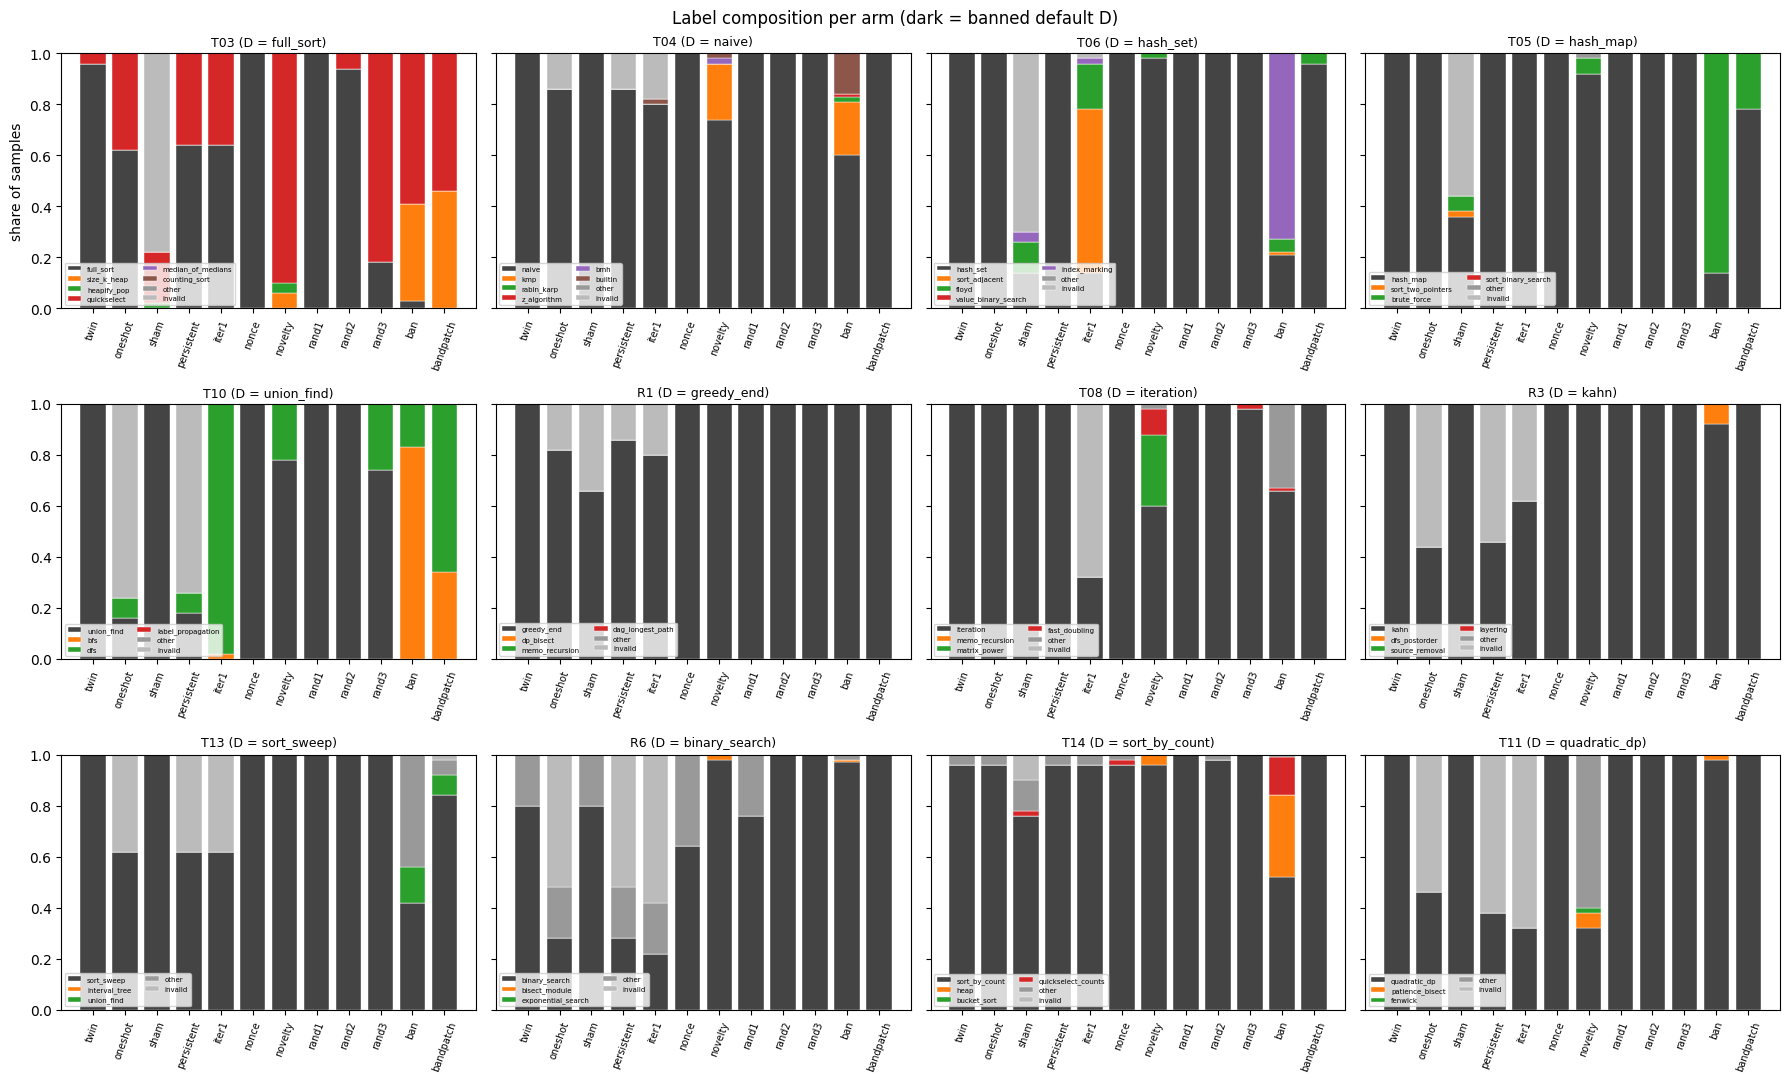

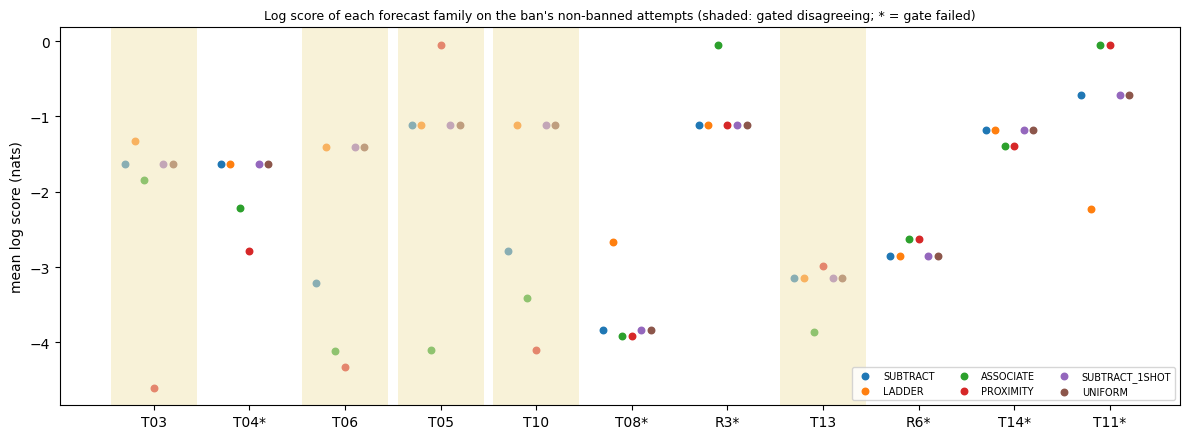

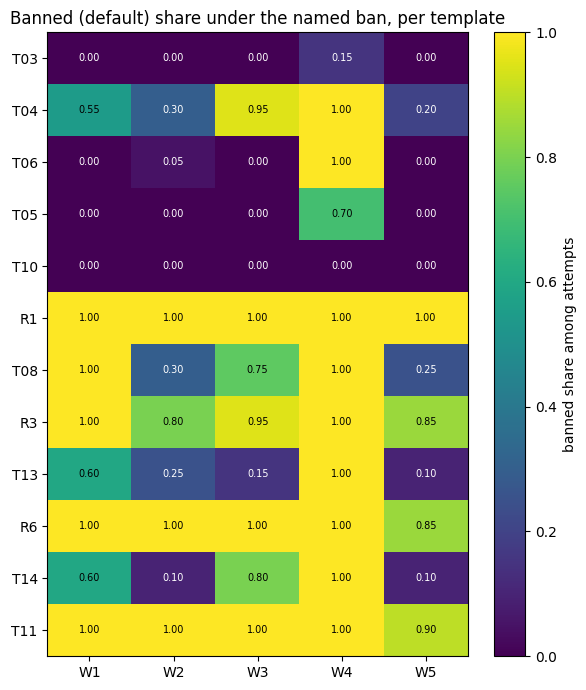

written: ['figures/composition_per_task.png', 'figures/logscores_by_family.png', 'figures/template_task_banned_share.png']


In [34]:
# analyze.run(): figures
res["figures"] = figures(arms, events, res["c2b"], res["template_effect"])
print("written:", res["figures"])

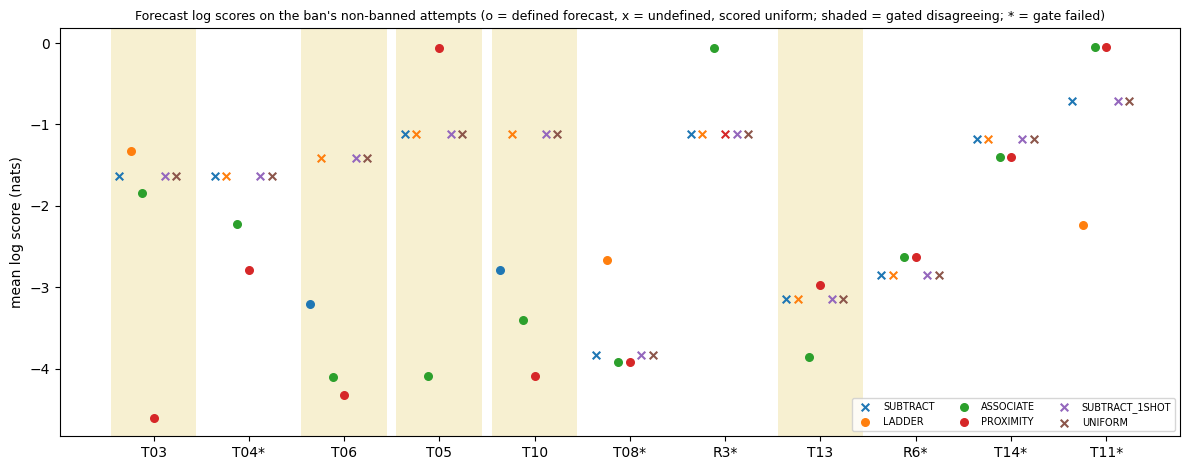

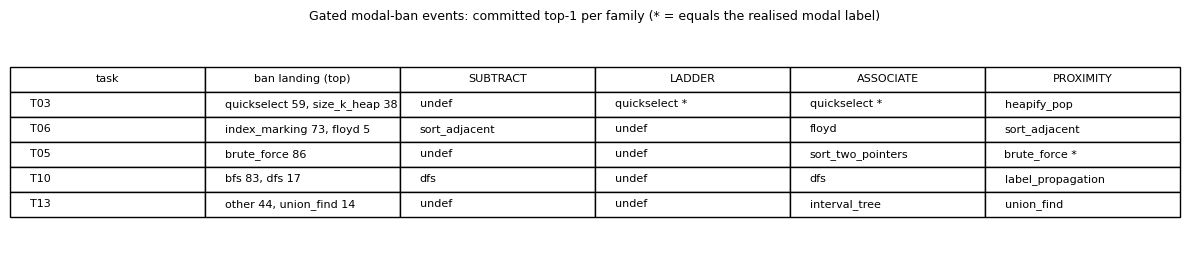

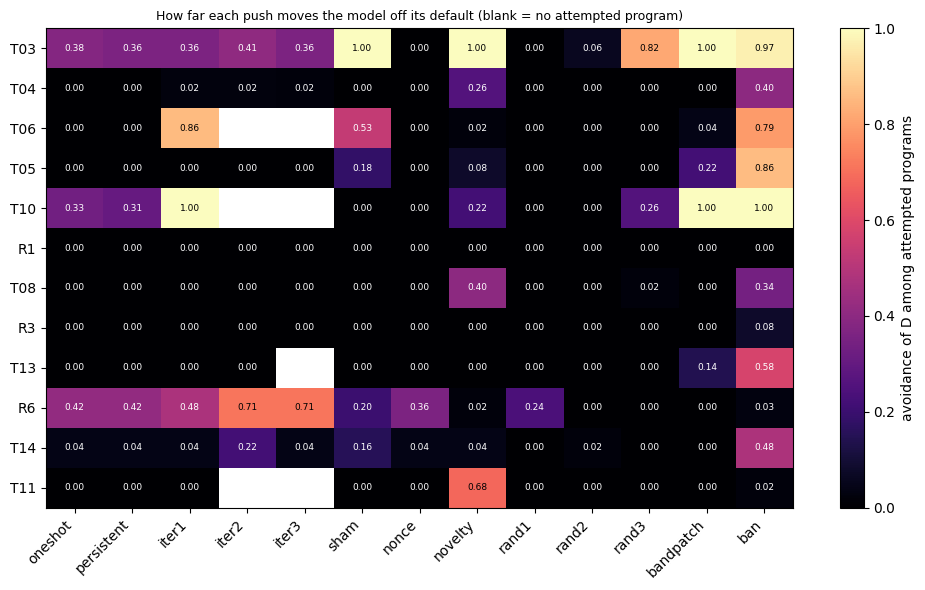

In [35]:
"""Extra figures drawn from the committed analysis outputs (no new numbers):
(1) the log-score plot redrawn with the shading behind the points (the committed analyze.py draws it on top);
(2) a forecast-vs-realised table figure for the gated events;
(3) avoidance of every push vs the named ban per task (heatmap)."""

FAMS = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY", "SUBTRACT_1SHOT", "UNIFORM"]


def logscores() -> None:
    ev = [e for e in events if e["n_non_banned"] > 0]  # read_jsonl(RESULTS / "c1_events.jsonl")
    fig, ax = plt.subplots(figsize=(12, 4.8))
    for i, e in enumerate(ev):
        if e["disagreeing"] and e["gate_pass"]:
            ax.axvspan(i - 0.45, i + 0.45, color="#f3e6b3", alpha=0.6, lw=0, zorder=0)
    mk = {True: "o", False: "x"}
    for j, f in enumerate(FAMS):
        xs = np.arange(len(ev)) + (j - len(FAMS) / 2) * 0.12
        for x, e in zip(xs, ev):
            ax.scatter(x, e["logscore"][f], color=plt.get_cmap("tab10")(j), marker=mk[bool(e["defined"][f])],
                       s=30, zorder=3, label=f if e is ev[0] else None)
    ax.set_xticks(range(len(ev)))
    ax.set_xticklabels([e["task"] + ("" if e["gate_pass"] else "*") for e in ev])
    ax.set_ylabel("mean log score (nats)")
    ax.set_title("Forecast log scores on the ban's non-banned attempts (o = defined forecast, x = undefined, scored "
                 "uniform; shaded = gated disagreeing; * = gate failed)", fontsize=9)
    ax.legend(fontsize=7, ncol=3, loc="lower right")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIGS / f"logscores_by_family_v2.{ext}", dpi=150)
    plt.show()
    plt.close(fig)


def forecast_table() -> None:
    ev = [e for e in events if e["gate_pass"]]  # read_jsonl(RESULTS / "c1_events.jsonl")
    if not ev:  # notebook guard: no gated event when N_BAN_PER_T is tiny
        return
    cols = ["task", "ban landing (top)", "SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
    cells = []
    for e in ev:
        land = sorted(e["landing_counts"].items(), key=lambda kv: -kv[1])
        top = ", ".join(f"{k} {v}" for k, v in land[:2])
        cells.append([e["task"], top] + [(e["top1"][f] or "undef") + (" *" if e["top1"][f] in e["realised_top1"]
                                                                        else "") for f in FAMS[:4]])
    fig, ax = plt.subplots(figsize=(12, 0.5 + 0.45 * len(cells)))
    ax.axis("off")
    t = ax.table(cellText=cells, colLabels=cols, loc="center", cellLoc="left")
    t.auto_set_font_size(False)
    t.set_fontsize(8)
    t.scale(1, 1.4)
    ax.set_title("Gated modal-ban events: committed top-1 per family (* = equals the realised modal label)",
                 fontsize=9)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIGS / f"forecast_table.{ext}", dpi=150)
    plt.show()
    plt.close(fig)


def avoidance_heatmap() -> None:
    an = res  # read_json(RESULTS / "analysis.json")
    arms = ["oneshot", "persistent", "iter1", "iter2", "iter3", "sham", "nonce", "novelty", "rand1", "rand2", "rand3",
            "bandpatch", "ban"]
    pt = an["descriptives"]["per_task_arm"]
    M = np.full((len(TASK_ORDER), len(arms)), np.nan)
    for i, t in enumerate(TASK_ORDER):
        for j, a in enumerate(arms):
            v = pt.get(t, {}).get(a)
            if v and v.get("avoidance") is not None:
                M[i, j] = v["avoidance"]
    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.imshow(M, cmap="magma", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if M[i, j] < 0.6 else "black")
    ax.set_xticks(range(len(arms)))
    ax.set_xticklabels(arms, rotation=45, ha="right")
    ax.set_yticks(range(len(TASK_ORDER)))
    ax.set_yticklabels(TASK_ORDER)
    fig.colorbar(im, ax=ax, label="avoidance of D among attempted programs")
    ax.set_title("How far each push moves the model off its default (blank = no attempted program)", fontsize=9)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIGS / f"avoidance_by_arm.{ext}", dpi=150)
    plt.show()
    plt.close(fig)


logscores()
forecast_table()
avoidance_heatmap()

## 17. Results: replay vs. original run
This table puts the headline numbers from this notebook next to those stored from the original run (`results/analysis.json`, `posthoc_sensitivity.json` and `rederive.json`).

The mixed-GLM standard deviations come from variational Bayes. They can differ in the second decimal across statsmodels versions; Colab's version is older than the run's.

In [36]:
ref = data["metadata"]["reference"]


def _w(w, nd=None):
    return ", ".join(f"{k} {v:.{nd}f}" if nd else f"{k} {v}" for k, v in w.items()) if w else "-"


def _f(x):
    return "-" if x is None else f"{x:+.2f}"


def _lr(d):
    return f"{d['LR']:.1f} (df {d['df']}), p = {d['p']:.2g}" if d.get("defined") else "undefined"


def _sd(m):
    return " / ".join(f"{s:.2f}" for s in m["sd_point"]) if m.get("defined") else "undefined"


def _else(c):
    el = [x for x in c["events"] if x.get("eligible")]
    return "; ".join(f"{x['task']}: veto {x['modal_veto']} vs ban {x['modal_ban']}" for x in el) or "-"


def _tp(d):
    return f"{d['p_real']:.3f} / {d['p_placebo_shuffled']:.3f}"


summary = [
    ("C1 verdict (frozen rule)", res["c1"]["verdict"], ref["c1"]["verdict"]),
    ("gated events", ", ".join(res["c1"]["gated_tasks"]) or "-", ", ".join(ref["c1"]["gated_tasks"])),
    ("C1 wins, frozen rule", _w(res["c1"]["advance"]["wins"]), _w(ref["c1"]["advance"]["wins"])),
    ("C1 wins, defined forecasts only (post-hoc)", _w(posthoc_out["defined_only_advance"]["wins"]),
     _w(ref["posthoc"]["defined_only_wins"])),
]
for f in PRIMARY:
    summary.append((f"mean log score minus uniform, {f}", _f(posthoc_out["vs_uniform_gated"][f]["mean_diff_vs_uniform"]),
                    _f(ref["posthoc"]["vs_uniform_gated"][f]["mean_diff_vs_uniform"])))
summary += [
    ("C2b verdict, one-shot veto (n eligible)", f"{res['c2b']['oneshot']['verdict']} ({res['c2b']['oneshot']['n_eligible']})",
     f"{ref['c2b']['oneshot']['verdict']} ({ref['c2b']['oneshot']['n_eligible']})"),
    ("C2b, last iterated round: eligible events", _else(res["c2b"]["last_iterated"]), _else(ref["c2b"]["last_iterated"])),
    ("template effect: LR test", _lr(res["template_effect"]["fixed_effects_lr"]), _lr(ref["template_effect"]["fixed_effects_lr"])),
    ("template placebo (shuffled): LR test", _lr(res["template_effect_placebo_shuffled"]),
     _lr(ref["template_effect"]["placebo_template_shuffled"])),
    ("mixed GLM SD: template / template x task", _sd(res["template_effect"]["mixed_glm"]),
     _sd(ref["template_effect"]["mixed_glm"])),
    ("audit: mismatches", str(rederive_out["n_mismatches"]), str(ref["rederive"]["n_mismatches"])),
    ("audit placebo: mean wins, task-shuffled", _w(rederive_out["placebo_task_shuffled"]["mean_wins"], 2),
     _w(ref["rederive"]["placebo_task_shuffled"]["mean_wins"], 2)),
    ("audit: template permutation p, real / shuffled", _tp(rederive_out["template_permutation_test"]),
     _tp(ref["rederive"]["template_permutation_test"])),
]
summary_df = pd.DataFrame(summary, columns=["quantity", "this notebook", "original run"]).set_index("quantity")
summary_df["match"] = np.where(summary_df["this notebook"] == summary_df["original run"], "yes", "no")
with pd.option_context("display.max_colwidth", 90):
    display(summary_df)
print(f"{(summary_df['match'] == 'yes').sum()}/{len(summary_df)} headline quantities identical to the original run "
      f"(N_BAN_PER_T = {N_BAN_PER_T}; the original used 20)")

,this notebook,original run,match
quantity,,,
C1 verdict (frozen rule),SUBTRACTION/LADDER (LADDER),SUBTRACTION/LADDER (LADDER),yes
gated events,"T03, T06, T05, T10, T13","T03, T06, T05, T10, T13",yes
"C1 wins, frozen rule","SUBTRACT 0, LADDER 3, ASSOCIATE 0, PROXIMITY 2","SUBTRACT 0, LADDER 3, ASSOCIATE 0, PROXIMITY 2",yes
"C1 wins, defined forecasts only (post-hoc)","SUBTRACT 0, LADDER 1, ASSOCIATE 0, PROXIMITY 2","SUBTRACT 0, LADDER 1, ASSOCIATE 0, PROXIMITY 2",yes
"mean log score minus uniform, SUBTRACT",-0.69,-0.69,yes
"mean log score minus uniform, LADDER",+0.06,+0.06,yes
"mean log score minus uniform, ASSOCIATE",-1.78,-1.78,yes
"mean log score minus uniform, PROXIMITY",-1.53,-1.53,yes
"C2b verdict, one-shot veto (n eligible)",UNDETERMINED (0),UNDETERMINED (0),yes


16/16 headline quantities identical to the original run (N_BAN_PER_T = 20; the original used 20)


The last figure puts the three findings side by side:
- **(a)** where each ban lands, including how often D survives;
- **(b)** how each family's forecast scored on the gated events relative to the uniform reference, labelled with its top-1 guess;
- **(c)** how big the ban is in activation space: the mean norm of the ban-minus-twin displacement of the task-spec residual states at layers 12-23. The random-direction pushes were matched to this norm.

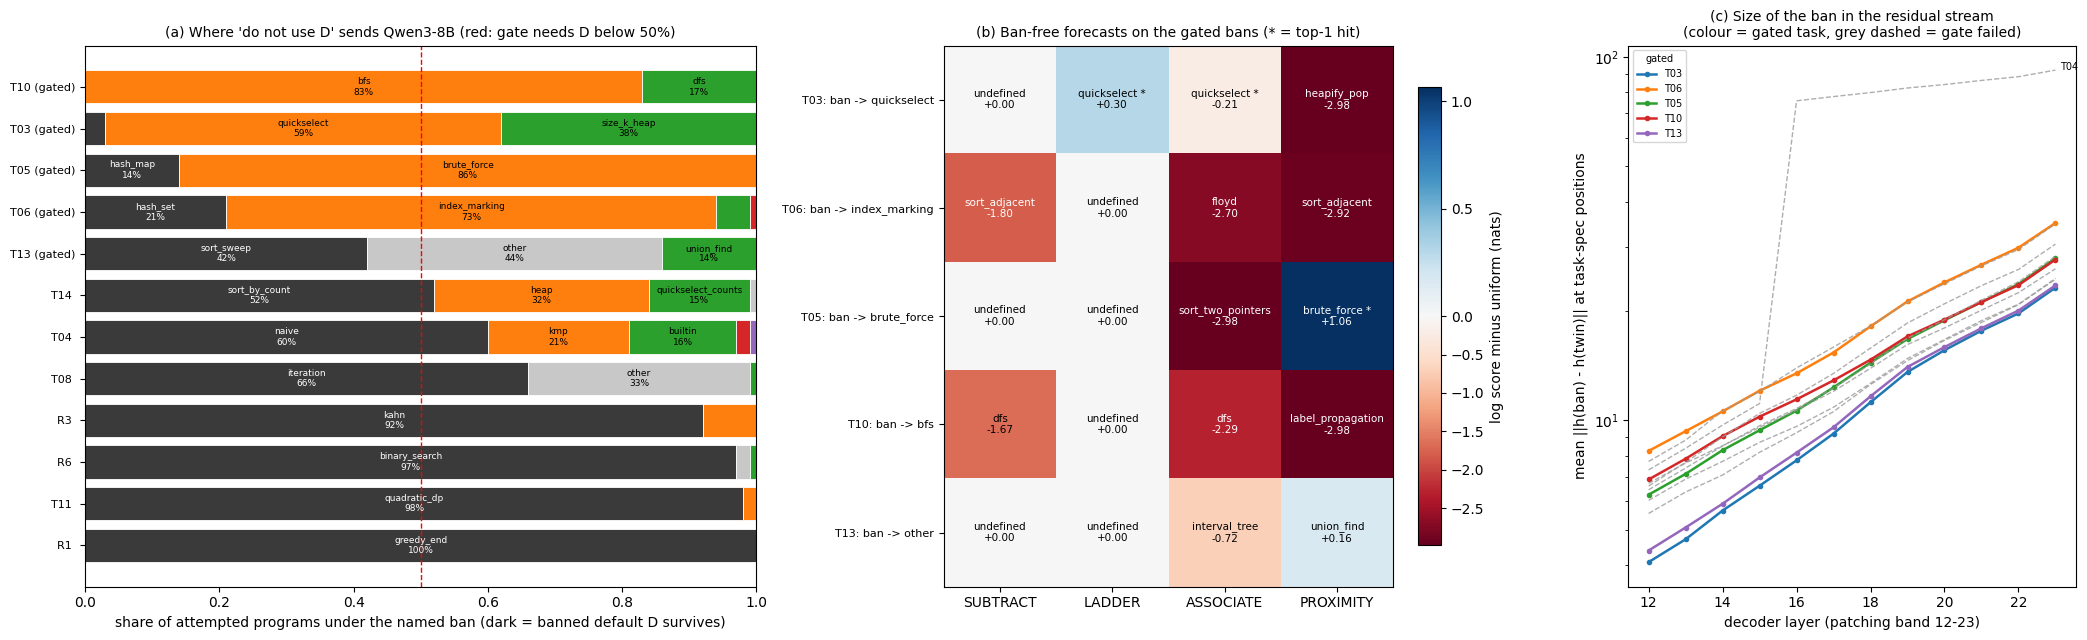

In [37]:
from matplotlib.colors import TwoSlopeNorm

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), gridspec_kw={"width_ratios": [1.35, 1.0, 0.9]})
pta = res["descriptives"]["per_task_arm"]

# (a) ban composition per task: D share + landing shares, tasks sorted by avoidance
ax = axes[0]
order = sorted([t for t in TASK_ORDER if pta[t].get("ban")], key=lambda t: pta[t]["ban"]["avoidance"])
cmap = plt.get_cmap("tab20")
for i, t in enumerate(order):
    b = pta[t]["ban"]
    n = b["n_attempted"]
    segs = [(DEFAULTS[t], b["n_default"])] + sorted(b["landing"].items(), key=lambda kv: -kv[1])
    left = 0.0
    for j, (lab, k) in enumerate(segs):
        w = k / n
        col = "#3a3a3a" if lab == DEFAULTS[t] else "#c8c8c8" if lab == "other" else cmap((2 * j) % 20)
        ax.barh(i, w, left=left, color=col, edgecolor="white", linewidth=0.6)
        if w >= 0.12:
            ax.text(left + w / 2, i, f"{lab}\n{w:.0%}", ha="center", va="center", fontsize=6.5,
                    color="white" if lab == DEFAULTS[t] else "black")
        left += w
ev_by_t = {e["task"]: e for e in events}
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{t} {'(gated)' if ev_by_t.get(t, {}).get('gate_pass') else ''}" for t in order], fontsize=8)
ax.axvline(1 - FROZEN_CONSTANTS["gate"]["min_avoidance"], color="red", ls="--", lw=1)
ax.set_xlim(0, 1)
ax.set_xlabel("share of attempted programs under the named ban (dark = banned default D survives)")
ax.set_title("(a) Where 'do not use D' sends Qwen3-8B (red: gate needs D below 50%)", fontsize=10)

# (b) log score minus uniform per gated event and family, annotated with the family's top-1
ax = axes[1]
gated = [e for e in events if e["gate_pass"]]
if gated:
    M = np.array([[e["logscore"][f] - e["logscore"]["UNIFORM"] for f in PRIMARY] for e in gated])
    nrm = TwoSlopeNorm(vcenter=0.0, vmin=min(-0.5, M.min()), vmax=max(0.5, M.max()))
    im = ax.imshow(M, cmap="RdBu", norm=nrm, aspect="auto")
    for i, e in enumerate(gated):
        for j, f in enumerate(PRIMARY):
            ax.text(j, i, f"{e['top1'][f] or 'undefined'}{' *' if e['hits'][f] else ''}\n{M[i, j]:+.2f}",
                    ha="center", va="center", fontsize=7.5,
                    color="white" if abs(float(nrm(M[i, j])) - 0.5) > 0.3 else "black")
    ax.set_xticks(range(len(PRIMARY)))
    ax.set_xticklabels(PRIMARY)
    ax.set_yticks(range(len(gated)))
    ax.set_yticklabels([f"{e['task']}: ban -> {'/'.join(e['realised_top1'])}" for e in gated], fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, label="log score minus uniform (nats)")
else:
    ax.text(0.5, 0.5, f"no gated event at N_BAN_PER_T = {N_BAN_PER_T}", ha="center", va="center")
    ax.axis("off")
ax.set_title("(b) Ban-free forecasts on the gated bans (* = top-1 hit)", fontsize=10)

# (c) activation space: ban-minus-twin displacement norm across the patching band
ax = axes[2]
ns = data["metadata"]["norms_summary"]
last = {t: ns[t]["mean_norm_per_layer"][-1] for t in TASK_ORDER}
for t in TASK_ORDER:
    g = ev_by_t.get(t, {}).get("gate_pass")
    ax.plot(BAND, ns[t]["mean_norm_per_layer"], marker="o" if g else None, ms=3, lw=1.8 if g else 1,
            ls="-" if g else "--", color=None if g else "#9a9a9a", label=t if g else None, alpha=1 if g else 0.8)
    if not g and last[t] > 2 * np.median(list(last.values())):  # name the outlying non-gated curves
        ax.annotate(t, (BAND[-1], last[t]), fontsize=7, xytext=(3, 0), textcoords="offset points")
ax.set_yscale("log")
ax.set_xlabel("decoder layer (patching band 12-23)")
ax.set_ylabel("mean ||h(ban) - h(twin)|| at task-spec positions")
ax.set_title("(c) Size of the ban in the residual stream\n(colour = gated task, grey dashed = gate failed)", fontsize=10)
ax.legend(fontsize=7, title="gated", title_fontsize=7)
fig.tight_layout()
plt.show()

### Reading the results
- **Bans often fail on this collapsed model.** On 7 of 12 tasks the named ban leaves the default in at least half the programs. Wording matters: the template random effect has an SD of about 2 logits.
- **Where gated bans land is mostly unforeseen.** T06's cyclic index marking, T10's BFS and T13's unsorted merge sweep were named as top-1 by no defined forecast. Only T03 (quickselect) and T05 (brute force) were hit.
- **The frozen verdict needs care.** "SUBTRACTION/LADDER (LADDER)" depends on LADDER being *undefined*, and hence uniform, on T06 and T10. Counting defined forecasts only, no family advances, and none beats uniform on average.
- **Token vetoes move the surface, not the algorithm.** One-shot vetoes never reach 0.5 avoidance on a gated task, so C2b is undetermined. Where the iterated vetoes do move the model, they land elsewhere than the ban.

**Scaling back to the full run.** The CPU analysis above already runs at the original sizes. Re-running the GPU stages needs the repository (`method.py all`, with `src/`, `inputs/` and an RTX-4090-class GPU, about 45 min). The steps are in the artifact's `reproducibility.md`.